In [1]:
import pandas as pd

In [2]:
cpi = pd.read_csv("/Users/aishwarya/Downloads/Stats/Project/Dataset/CPI_health.csv",encoding = "ISO-8859-1")

In [3]:
gov_exp = pd.read_csv("/Users/aishwarya/Downloads/Stats/Project/Dataset/GovernmentHealthExpenditureAnnual.csv",encoding = "ISO-8859-1")

In [4]:
pop_agegroup = pd.read_csv("/Users/aishwarya/Downloads/Stats/Project/Dataset/Population_by_agegroup.csv", encoding = "ISO-8859-1")

In [5]:
gdp = pd.read_csv("/Users/aishwarya/Downloads/Stats/Project/Dataset/GDP_data.csv",encoding = "ISO-8859-1")

In [6]:
workforce = pd.read_csv("/Users/aishwarya/Downloads/Stats/Project/Dataset/Workforce_data.csv",encoding = "ISO-8859-1")

In [7]:
cpi_new = cpi.iloc[:2,:15]  # filtering health cpi
cpi_new

,Data Series,2024,2023,2022,2021,2020,2019,2018,2017,2016,2015,2014,2013,2012,2011
0,All Items,100.0,97.340,93.342,88.863,87.377,87.430,87.170,86.975,87.074,88.004,88.977,87.619,85.302,80.801
1,Health,100.0,96.082,96.175,95.226,94.350,96.496,95.217,92.945,90.021,90.696,93.71,91.007,87.578,83.508


In [8]:
cpi_transposed = cpi_new.set_index('Data Series').T
cpi_transposed = cpi_transposed.astype(float)

# Round to 2 decimal places
cpi_transposed = cpi_transposed.round(2)
cpi_transposed.reset_index(inplace=True)
cpi_transposed = cpi_transposed.rename(columns={"index":"Year","All Items":"General_cpi", "  Health":"Health_cpi"})
cpi_transposed['Year'] = cpi_transposed['Year'].str.strip()

# Display the result
print(cpi_transposed)


Data Series  Year  General_cpi  Health_cpi
0            2024       100.00      100.00
1            2023        97.34       96.08
2            2022        93.34       96.18
3            2021        88.86       95.23
4            2020        87.38       94.35
5            2019        87.43       96.50
6            2018        87.17       95.22
7            2017        86.98       92.94
8            2016        87.07       90.02
9            2015        88.00       90.70
10           2014        88.98       93.71
11           2013        87.62       91.01
12           2012        85.30       87.58
13           2011        80.80       83.51


# Feature Engineering


In [9]:
cpi_transposed['General Inflation %'] = ((cpi_transposed['General_cpi'] - cpi_transposed['General_cpi'].shift(-1)) / cpi_transposed['General_cpi'].shift(-1) * 100).round(2)
cpi_transposed['Health Inflation %'] = ((cpi_transposed['Health_cpi'] - cpi_transposed['Health_cpi'].shift(-1)) / cpi_transposed['Health_cpi'].shift(-1) * 100).round(2)
cpi_transposed = cpi_transposed[cpi_transposed["Year"]!= '2011']
cpi_transposed

Data Series,Year,General_cpi,Health_cpi,General Inflation %,Health Inflation %
0,2024,100.00,100.00,2.73,4.08
1,2023,97.34,96.08,4.29,-0.10
2,2022,93.34,96.18,5.04,1.00
3,2021,88.86,95.23,1.69,0.93
4,2020,87.38,94.35,-0.06,-2.23
5,2019,87.43,96.50,0.30,1.34
6,2018,87.17,95.22,0.22,2.45
7,2017,86.98,92.94,-0.10,3.24
8,2016,87.07,90.02,-1.06,-0.75
9,2015,88.00,90.70,-1.10,-3.21


In [10]:
gov_exp = gov_exp.iloc[:,:15]
gov_exp.head(10)

,DataSeries,2025,2024,2023,2022,2021,2020,2019,2018,2017,2016,2015,2014,2013,2012
0,Per Capita Government Health Expenditure,na,na,na,2976.0,3101.0,2674.0,1954.0,1795.0,1744.0,1657.0,1561.0,1321.0,1100.0,911.0
1,Government Health Expenditure,na,na,na,16773.8,16913.7,15202.8,11147.1,10122.7,9764.3,9307.0,8639.9,7223.1,5938.1,4837.3
2,Proportion Of Government Expenditure On Health...,na,na,na,2.5,2.9,3.2,2.2,2.1,2.1,2.1,2.0,1.8,1.5,1.3
3,Development Expenditure On Health,2067.9,1206.6,1323.4,1203.8,1048.8,949.2,1403.9,1490.3,1465.4,1619.2,1413.1,1146.8,722.9,605.4
4,Operating Expenditure On Health,18795.3,16731,15935.4,15908.6,16273.7,14310.6,9914.8,8937.4,8734.4,8199.4,7519.8,5872.4,5043.9,4066.1


In [11]:
gov_exp_transposed = gov_exp.set_index('DataSeries').T
gov_exp_transposed

DataSeries,Per Capita Government Health Expenditure,Government Health Expenditure,Proportion Of Government Expenditure On Health To GDP,Development Expenditure On Health,Operating Expenditure On Health
2025,na,na,na,2067.9,18795.3
2024,na,na,na,1206.6,16731
2023,na,na,na,1323.4,15935.4
2022,2976.0,16773.8,2.5,1203.8,15908.6
2021,3101.0,16913.7,2.9,1048.8,16273.7
2020,2674.0,15202.8,3.2,949.2,14310.6
2019,1954.0,11147.1,2.2,1403.9,9914.8
2018,1795.0,10122.7,2.1,1490.3,8937.4
2017,1744.0,9764.3,2.1,1465.4,8734.4
2016,1657.0,9307.0,2.1,1619.2,8199.4


In [12]:
gov_exp_transposed['Development Expenditure On Health'] = gov_exp_transposed['Development Expenditure On Health'].astype(float)
gov_exp_transposed['Operating Expenditure On Health'] = gov_exp_transposed['Operating Expenditure On Health'].astype(float)

In [13]:
gov_exp_transposed['Total Government Health Expenditure'] = gov_exp_transposed['Development Expenditure On Health'] + gov_exp_transposed['Operating Expenditure On Health']

In [14]:
gov_exp_transposed

DataSeries,Per Capita Government Health Expenditure,Government Health Expenditure,Proportion Of Government Expenditure On Health To GDP,Development Expenditure On Health,Operating Expenditure On Health,Total Government Health Expenditure
2025,na,na,na,2067.9,18795.3,20863.2
2024,na,na,na,1206.6,16731.0,17937.6
2023,na,na,na,1323.4,15935.4,17258.8
2022,2976.0,16773.8,2.5,1203.8,15908.6,17112.4
2021,3101.0,16913.7,2.9,1048.8,16273.7,17322.5
2020,2674.0,15202.8,3.2,949.2,14310.6,15259.8
2019,1954.0,11147.1,2.2,1403.9,9914.8,11318.7
2018,1795.0,10122.7,2.1,1490.3,8937.4,10427.7
2017,1744.0,9764.3,2.1,1465.4,8734.4,10199.8
2016,1657.0,9307.0,2.1,1619.2,8199.4,9818.6


In [15]:
gov_exp_transposed.reset_index(inplace=True)
gov_exp_transposed = gov_exp_transposed.rename(columns={"index":"Year"})
gov_exp_transposed['Year'] = gov_exp_transposed['Year'].str.strip()

In [16]:
pop_agegroup = pop_agegroup.iloc[:,:15]
pop_agegroup

,Data Series,2025,2024,2023,2022,2021,2020,2019,2018,2017,2016,2015,2014,2013,2012
0,Total Population,6111175,6036860,5917648,5637022,5453566,5685807,5703569,5638676,5612253,5607283,5535002,5469724,5399162,5312437
1,Total-0 - 14 Years,668605,677425,681459,675638,670531,688984,694083,693674,696073,697821,700306,701810,703792,708720
2,Total-15 - 64 Years,4576167,4530831,4451242,4226527,4087584,4320933,4368610,4340925,4347598,4372906,4328454,4291920,4247923,4184350
3,Total-65 Years & Over,866403,828604,784947,734857,695451,675890,640876,604077,568582,536556,506242,475994,447447,419367
4,Total Male Population,3142716,3103862,3051224,2890541,2771567,2912155,2926359,2893284,2897264,2920951,2891101,2864408,2824655,2765614
5,Male-0 - 14 Years,343135,347395,349387,346234,344164,353100,355638,355654,356764,357709,359115,360167,361488,363972
6,Male-15 - 64 Years,2405364,2379823,2345368,2210238,2112426,2253450,2281276,2265857,2285455,2323009,2306077,2292707,2265175,2216693
7,Male-65 Years & Over,394217,376644,356469,334069,314977,305605,289445,271773,255045,240233,225909,211534,197992,184949
8,Total Female Population,2968459,2932998,2866424,2746481,2681999,2773652,2777210,2745392,2714989,2686332,2643901,2605316,2574507,2546823
9,Female-0 - 14 Years,325470,330030,332072,329404,326367,335884,338445,338020,339309,340112,341191,341643,342304,344748


In [17]:
pop_transposed = pop_agegroup.set_index('Data Series').T
pop_transposed

Data Series,Total Population,Total-0 - 14 Years,Total-15 - 64 Years,Total-65 Years & Over,Total Male Population,Male-0 - 14 Years,Male-15 - 64 Years,Male-65 Years & Over,Total Female Population,Female-0 - 14 Years,Female-15 - 64 Years,Female-65 Years & Over
2025,6111175,668605,4576167,866403,3142716,343135,2405364,394217,2968459,325470,2170803,472186
2024,6036860,677425,4530831,828604,3103862,347395,2379823,376644,2932998,330030,2151008,451960
2023,5917648,681459,4451242,784947,3051224,349387,2345368,356469,2866424,332072,2105874,428478
2022,5637022,675638,4226527,734857,2890541,346234,2210238,334069,2746481,329404,2016289,400788
2021,5453566,670531,4087584,695451,2771567,344164,2112426,314977,2681999,326367,1975158,380474
2020,5685807,688984,4320933,675890,2912155,353100,2253450,305605,2773652,335884,2067483,370285
2019,5703569,694083,4368610,640876,2926359,355638,2281276,289445,2777210,338445,2087334,351431
2018,5638676,693674,4340925,604077,2893284,355654,2265857,271773,2745392,338020,2075068,332304
2017,5612253,696073,4347598,568582,2897264,356764,2285455,255045,2714989,339309,2062143,313537
2016,5607283,697821,4372906,536556,2920951,357709,2323009,240233,2686332,340112,2049897,296323


In [18]:
pop_transposed.reset_index(inplace=True)
pop_transposed = pop_transposed.rename(columns={"index":"Year"})
pop_transposed['Year'] = pop_transposed['Year'].str.strip()

In [19]:
gdp_transposed = gdp.set_index('DataSeries').T
gdp_transposed

DataSeries,Per Capita GNI,Per Capita GDP,Per Capita GNI (US Dollar),Per Capita GDP (US Dollar)
2024,101464,121161,75946,90689
2023,93592,114690,69684,85392
2022,99553,124493,72197,90284
2021,91402,107553,68007,80025
2020,73864,84730,53556,61434
...,...,...,...,...
1964,1533,1486,501,485
1963,1603,1565,524,511
1962,1473,1445,481,472
1961,1401,1375,458,449


In [20]:
gdp_transposed.reset_index(inplace=True)
gdp_transposed = gdp_transposed.rename(columns={"index":"Year"})
gdp_transposed['Year'] = gdp_transposed['Year'].str.strip()

In [21]:
gdp_transposed = gdp_transposed[['Year','Per Capita GNI', 'Per Capita GDP']]

In [22]:
workforce.head(5)

,year,number of public nurses,number of public doctors,number of public acute & community hospital beds
0,2009,15577,4610,6416
1,2010,17519,5180,6871
2,2011,19155,5621,7025
3,2012,20911,6131,7270
4,2013,21628,6661,7487


In [23]:
workforce = workforce.rename(columns={"year":"Year"})
workforce = workforce.rename(columns={"number of public doctors":"Doctors"})
workforce = workforce.rename(columns={"number of public nurses":"Nurses"})
workforce = workforce.rename(columns={"number of public acute & community hospital beds":"Beds"})

In [24]:
#Join datasets (2012-2024
final = pd.merge(cpi_transposed, gov_exp_transposed, on='Year', how ='left')
final = pd.merge(final, pop_transposed, on='Year', how='left')
final = pd.merge(final, gdp_transposed, on='Year', how='left')
final['Year'] = pd.to_numeric(final['Year'], errors='coerce').fillna(0).astype(int)
final = pd.merge(final, workforce, on='Year', how='left')

In [25]:
final.reset_index(inplace=True)
#final['Year'] = pd.to_numeric(final['Year'], errors='coerce').fillna(0).astype(int)
final['Per Capita Government Health Expenditure-Calculated'] = final['Total Government Health Expenditure']/final['Total Population']
final.dtypes

index                                                      int64
Year                                                       int64
General_cpi                                              float64
Health_cpi                                               float64
General Inflation %                                      float64
Health Inflation %                                       float64
Per Capita Government Health Expenditure                  object
Government Health Expenditure                             object
Proportion Of Government Expenditure On Health To GDP     object
Development Expenditure On Health                        float64
Operating Expenditure On Health                          float64
Total Government Health Expenditure                      float64
Total Population                                           int64
Total-0 - 14 Years                                         int64
Total-15 - 64 Years                                        int64
Total-65 Years & Over    

In [26]:
final.drop('Government Health Expenditure', axis=1, inplace=True)
final.drop('Per Capita Government Health Expenditure', axis=1, inplace=True)

In [27]:
final["Oper. Exp. Per Capita"] = final["Operating Expenditure On Health"]/final["Total Population"]
final["Dev. Exp. Per Capita"] = final["Development Expenditure On Health"]/final["Total Population"]
final["Doc Per Capita"] = final["Doctors"]/final["Total Population"]
final["Nurse Per Capita"] = final["Nurses"]/final["Total Population"]
final["No. of Beds Per Capita"] = final["Beds"]/final["Total Population"]

In [28]:
# ── Additional derived columns ────────────────────────────────────────────
import pandas as pd, numpy as np

total_pop = pd.to_numeric(final['Total Population'],               errors='coerce')
oper_exp  = pd.to_numeric(final['Operating Expenditure On Health'], errors='coerce')
dev_exp   = pd.to_numeric(final['Development Expenditure On Health'],errors='coerce')

# ── 65+ population: use Total-65 Years & Over directly from pop_transposed ─
pop65 = pd.to_numeric(final['Total-65 Years & Over'], errors='coerce')
final['Pop 65+ Total'] = pop65
final['Aging Ratio']   = (pop65 / total_pop * 100).round(2)

# ── Workforce per 1,000 population (kept for reference/ratio) ─────────────
final['Docs per 1000']   = (pd.to_numeric(final['Doctors'],errors='coerce') / total_pop * 1000).round(3)
final['Nurses per 1000'] = (pd.to_numeric(final['Nurses'], errors='coerce') / total_pop * 1000).round(3)
final['Beds per 1000']   = (pd.to_numeric(final['Beds'],   errors='coerce') / total_pop * 1000).round(3)
final['Nurse Doc Ratio'] = (pd.to_numeric(final['Nurses'],errors='coerce') /
                             pd.to_numeric(final['Doctors'],errors='coerce')).round(3)

# ── Budget composition ────────────────────────────────────────────────────
final['Dev Budget Share %'] = (dev_exp / (oper_exp + dev_exp) * 100).round(1)

# ── Health Exp % GDP: official source for 2012-2022; computed for 2023-2024 ─
# Official source (gov_exp_transposed): 'Proportion Of Government Expenditure On Health To GDP'
# 2023/2024 not yet published → compute from: Total Gov Health Exp / (Per Capita GDP × Total Population)
health_pct_src = pd.to_numeric(
    final['Proportion Of Government Expenditure On Health To GDP'], errors='coerce')
per_cap_gdp    = pd.to_numeric(final['Per Capita GDP'], errors='coerce')
total_gov_exp  = pd.to_numeric(final['Total Government Health Expenditure'], errors='coerce')
# Total GDP in SGD M = Per Capita GDP (SGD) × Population / 1e6
total_gdp_m    = per_cap_gdp * total_pop / 1e6
# Computed % for all years (as cross-check and fill for 2023/2024)
health_pct_calc = (total_gov_exp / total_gdp_m * 100).round(2)
# Use official where available, computed where 'na' (2023/2024)
final['Health Exp % GDP'] = health_pct_src.where(health_pct_src.notna(), health_pct_calc)
final['Health Exp % GDP Source'] = health_pct_src.apply(
    lambda v: 'Official' if pd.notna(v) else 'Computed')

# ── Indexed growth (2012 = 100) ────────────────────────────────────────────
base = final[final['Year'] == 2012].iloc[0]
final['Total Pop Index']    = (total_pop / base['Total Population']   * 100).round(1)
final['Pop65 Index']        = (pop65     / base['Pop 65+ Total']       * 100).round(1)
final['Oper Exp PC Index']  = (final['Oper. Exp. Per Capita'] / base['Oper. Exp. Per Capita'] * 100).round(1)
final['Docs Index']         = (pd.to_numeric(final['Doctors'],errors='coerce') / base['Doctors'] * 100).round(1)

print("Derived columns added successfully.")
print()
print("  Health Exp % GDP (official + computed for 2023/2024):")
print(f"  {'Year':>6}  {'Health Exp % GDP':>17}  {'Source':>10}  {'Calc Check':>11}")
print("  " + "-" * 52)
for _, row in final[['Year','Health Exp % GDP','Health Exp % GDP Source']].sort_values('Year').iterrows():
    calc = health_pct_calc.loc[row.name]
    print(f"  {int(row['Year']):>6}  {row['Health Exp % GDP']:>17.2f}  "
          f"{row['Health Exp % GDP Source']:>10}  {calc:>11.2f}")


Derived columns added successfully.

  Health Exp % GDP (official + computed for 2023/2024):
    Year   Health Exp % GDP      Source   Calc Check
  ----------------------------------------------------
    2012               1.30    Official         1.27
    2013               1.50    Official         1.50
    2014               1.80    Official         1.76
    2015               2.00    Official         2.11
    2016               2.10    Official         2.22
    2017               2.10    Official         2.15
    2018               2.10    Official         2.05
    2019               2.20    Official         2.21
    2020               3.20    Official         3.17
    2021               2.90    Official         2.95
    2022               2.50    Official         2.44
    2023               2.54    Computed         2.54
    2024               2.45    Computed         2.45


In [29]:
final.describe()

,index,Year,General_cpi,Health_cpi,General Inflation %,Health Inflation %,Development Expenditure On Health,Operating Expenditure On Health,Total Government Health Expenditure,Total Population,...,Docs per 1000,Nurses per 1000,Beds per 1000,Nurse Doc Ratio,Dev Budget Share %,Health Exp % GDP,Total Pop Index,Pop65 Index,Oper Exp PC Index,Docs Index
count,13.00000,13.00000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,1.300000e+01,...,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000
mean,6.00000,2018.00000,89.651538,93.809231,1.676154,1.423846,1199.907692,10572.884615,11772.792308,5.616078e+06,...,1.558000,4.562538,1.723000,2.953846,11.453846,2.206923,105.715385,145.246154,243.823077,143.223077
std,3.89444,3.89444,4.441570,3.317555,2.252826,2.486720,303.105874,4637.382215,4699.659495,1.990003e+05,...,0.226766,0.408216,0.234427,0.199840,4.100735,0.523408,3.737835,31.186499,102.664601,24.698048
min,0.00000,2012.00000,85.300000,87.580000,-1.100000,-3.210000,605.400000,4066.100000,4671.500000,5.312437e+06,...,1.154000,3.936000,1.368000,2.709000,6.100000,1.300000,100.000000,100.000000,100.000000,100.000000
25%,3.00000,2015.00000,87.170000,91.010000,-0.060000,-0.100000,1048.800000,7519.800000,8932.900000,5.469724e+06,...,1.429000,4.313000,1.559000,2.820000,7.000000,2.000000,103.000000,120.700000,177.500000,129.000000
50%,6.00000,2018.00000,87.620000,94.350000,1.550000,1.340000,1206.600000,8937.400000,10427.700000,5.612253e+06,...,1.564000,4.538000,1.750000,2.901000,12.500000,2.100000,105.600000,144.000000,207.100000,143.800000
75%,9.00000,2021.00000,88.980000,96.080000,2.730000,3.240000,1413.100000,15908.600000,17112.400000,5.685807e+06,...,1.789000,4.876000,1.907000,3.018000,14.400000,2.500000,107.000000,165.800000,351.800000,160.600000
max,12.00000,2024.00000,100.000000,100.000000,5.570000,4.870000,1619.200000,16731.000000,17937.600000,6.036860e+06,...,1.861000,5.307000,2.019000,3.411000,16.500000,3.200000,113.600000,197.600000,389.900000,183.200000


In [30]:
final

,index,Year,General_cpi,Health_cpi,General Inflation %,Health Inflation %,Proportion Of Government Expenditure On Health To GDP,Development Expenditure On Health,Operating Expenditure On Health,Total Government Health Expenditure,...,Nurses per 1000,Beds per 1000,Nurse Doc Ratio,Dev Budget Share %,Health Exp % GDP,Health Exp % GDP Source,Total Pop Index,Pop65 Index,Oper Exp PC Index,Docs Index
0,0,2024,100.00,100.00,2.73,4.08,na,1206.6,16731.0,17937.6,...,5.307,2.019,2.852,6.7,2.45,Computed,113.6,197.6,362.1,183.2
1,1,2023,97.34,96.08,4.29,-0.10,na,1323.4,15935.4,17258.8,...,4.962,1.907,2.774,7.7,2.54,Computed,111.4,187.2,351.8,172.7
2,2,2022,93.34,96.18,5.04,1.00,2.5,1203.8,15908.6,17112.4,...,4.876,1.960,2.709,7.0,2.50,Official,106.1,175.2,368.7,165.5
3,3,2021,88.86,95.23,1.69,0.93,2.9,1048.8,16273.7,17322.5,...,5.007,2.006,2.774,6.1,2.90,Official,102.7,165.8,389.9,160.6
4,4,2020,87.38,94.35,-0.06,-2.23,3.2,949.2,14310.6,15259.8,...,4.727,1.889,2.820,6.2,3.20,Official,107.0,161.2,328.8,155.5
5,5,2019,87.43,96.50,0.30,1.34,2.2,1403.9,9914.8,11318.7,...,4.565,1.820,2.883,12.4,2.20,Official,107.4,152.8,227.1,147.3
6,6,2018,87.17,95.22,0.22,2.45,2.1,1490.3,8937.4,10427.7,...,4.538,1.750,2.901,14.3,2.10,Official,106.1,144.0,207.1,143.8
7,7,2017,86.98,92.94,-0.10,3.24,2.1,1465.4,8734.4,10199.8,...,4.514,1.659,2.955,14.4,2.10,Official,105.6,135.6,203.3,139.8
8,8,2016,87.07,90.02,-1.06,-0.75,2.1,1619.2,8199.4,9818.6,...,4.417,1.650,2.963,16.5,2.10,Official,105.6,127.9,191.0,136.3
9,9,2015,88.00,90.70,-1.10,-3.21,2.0,1413.1,7519.8,8932.9,...,4.313,1.559,3.018,15.8,2.00,Official,104.2,120.7,177.5,129.0


In [31]:
final.isna().any()

index                                                    False
Year                                                     False
General_cpi                                              False
Health_cpi                                               False
General Inflation %                                      False
Health Inflation %                                       False
Proportion Of Government Expenditure On Health To GDP    False
Development Expenditure On Health                        False
Operating Expenditure On Health                          False
Total Government Health Expenditure                      False
Total Population                                         False
Total-0 - 14 Years                                       False
Total-15 - 64 Years                                      False
Total-65 Years & Over                                    False
Total Male Population                                    False
Male-0 - 14 Years                                      

In [32]:
final.to_csv('/Users/aishwarya/Downloads/final_merged.csv') 

# Exploratory Data Analysis
## Generating Visulatization

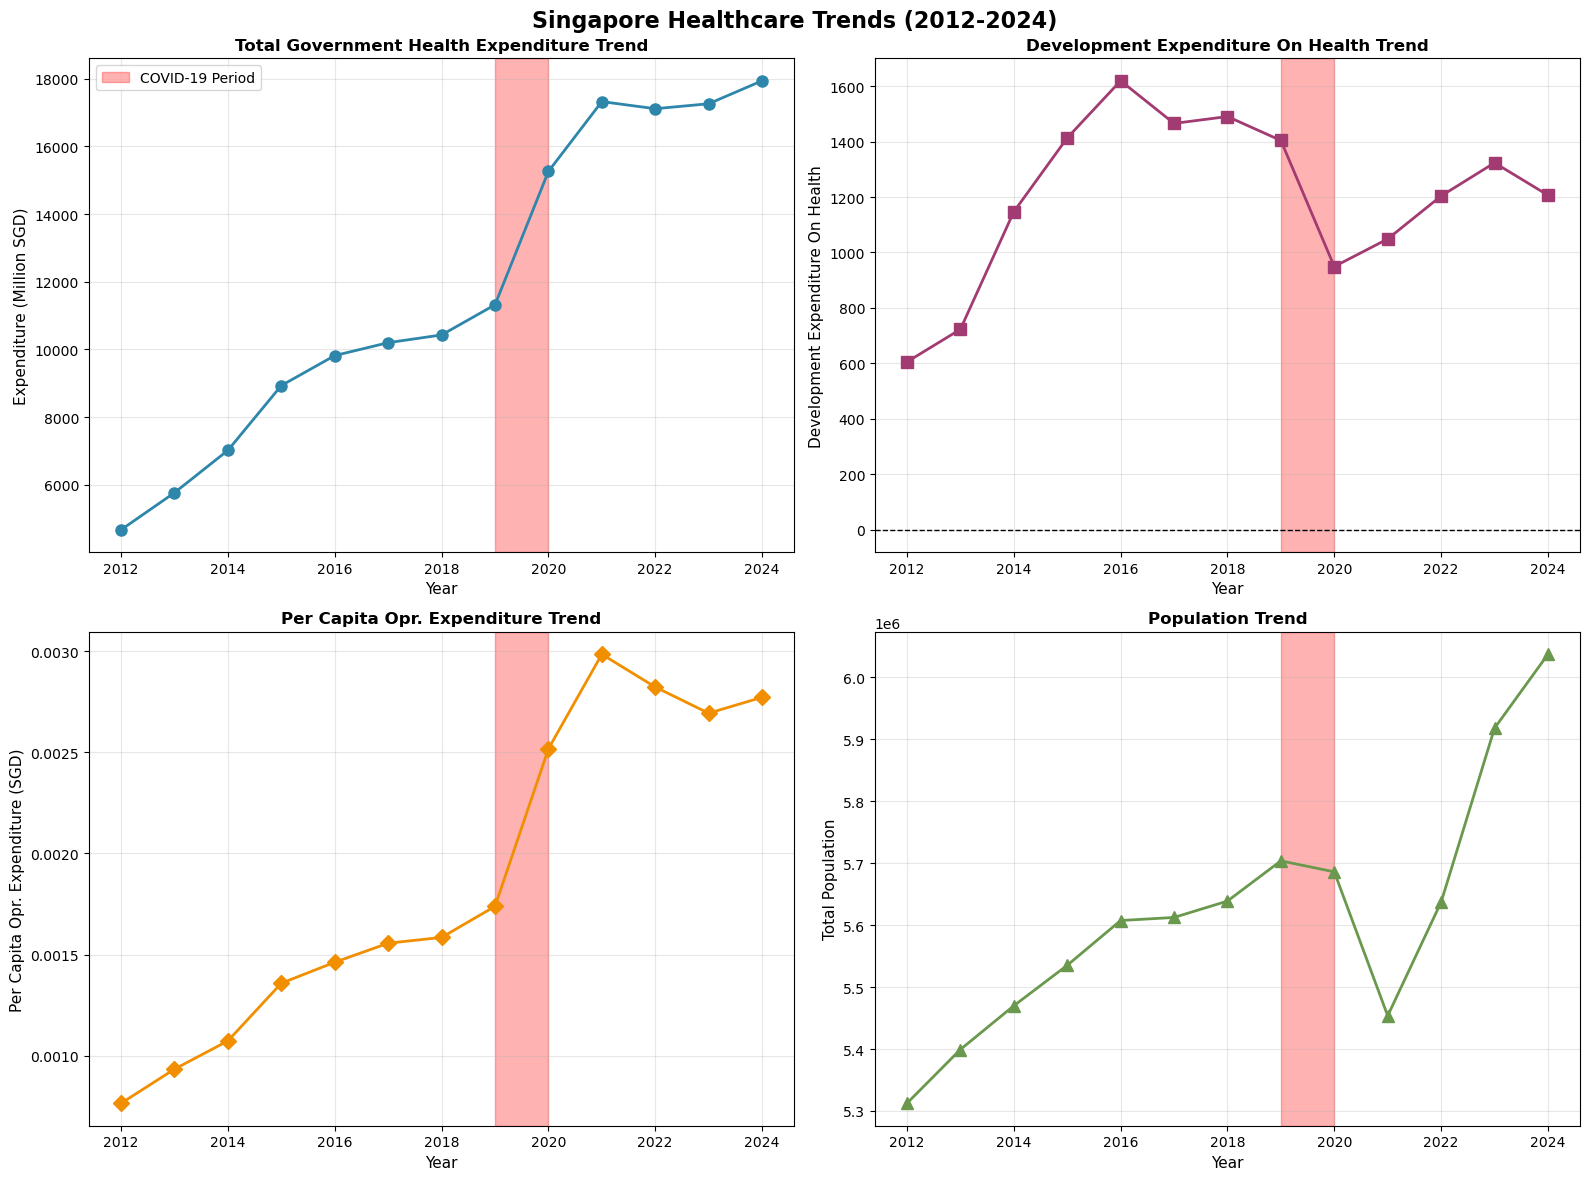

In [33]:
import matplotlib.pyplot as plt
import os
import numpy as np
os.makedirs('outputs', exist_ok=True)

final = final.sort_values(by='Year')

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Singapore Healthcare Trends (2012-2024)', fontsize=16, fontweight='bold')

# Plot 1: Total Government Health Expenditure
ax1 = axes[0, 0]
ax1.plot(final['Year'], final['Total Government Health Expenditure'], 
    marker='o', linewidth=2, markersize=8, color='#2E86AB')
ax1.axvspan(2019, 2020, alpha = 0.3, color='red', label='COVID-19 Period')
ax1.set_xlabel('Year', fontsize=11)
ax1.set_ylabel('Expenditure (Million SGD)', fontsize=11)
ax1.set_title('Total Government Health Expenditure Trend', fontsize=12, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend()

# Plot 2: Development Health Expenditure
ax2 = axes[0, 1]
ax2.plot(final['Year'], final['Development Expenditure On Health'], 
        marker='s', linewidth=2, markersize=8, color='#A23B72')
ax2.axvspan(2019, 2020, alpha = 0.3, color='red', label='COVID-19 Period')
ax2.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax2.set_xlabel('Year', fontsize=11)
ax2.set_ylabel('Development Expenditure On Health', fontsize=11)
ax2.set_title('Development Expenditure On Health Trend', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3)

# Plot 3: Per Capita Operating Health Expenditure
ax3 = axes[1, 0]
ax3.plot(final['Year'], final['Oper. Exp. Per Capita'], 
        marker='D', linewidth=2, markersize=8, color='#F18F01')
ax3.axvspan(2019, 2020, alpha = 0.3, color='red', label='COVID-19 Period')
ax3.set_xlabel('Year', fontsize=11)
ax3.set_ylabel('Per Capita Opr. Expenditure (SGD)', fontsize=11)
ax3.set_title('Per Capita Opr. Expenditure Trend', fontsize=12, fontweight='bold')
ax3.grid(True, alpha=0.3)

# Plot 4: Total Population
ax4 = axes[1, 1]
ax4.plot(final['Year'], final['Total Population'],
        marker='^', linewidth=2, markersize=8, color='#6A994E')
ax4.axvspan(2019, 2020, alpha = 0.3, color='red', label='COVID-19 Period')
ax4.set_xlabel('Year', fontsize=11)
ax4.set_ylabel('Total Population', fontsize=11)
ax4.set_title('Population Trend', fontsize=12, fontweight='bold')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


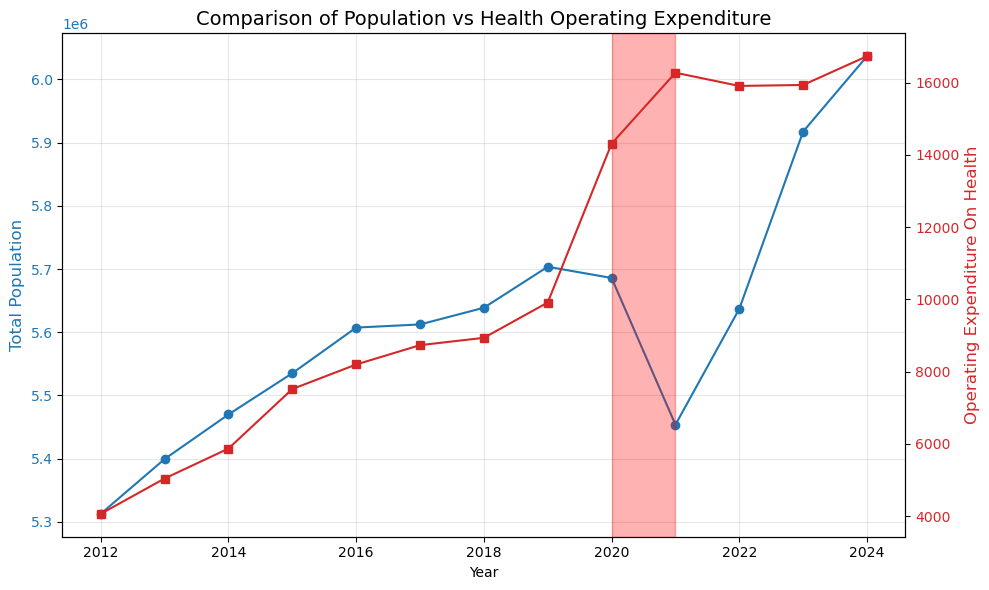

In [34]:
# Total Population vs Operating expenditure
import matplotlib.pyplot as plt

pop_vs_exp = final[['Year','Total Population','Operating Expenditure On Health']]
pop_vs_exp['Year'].astype(int)
pop_vs_exp = pop_vs_exp.sort_values(by='Year')

# 1. Create the figure and the first axis (ax1)
fig, ax1 = plt.subplots(figsize=(10, 6))

# 2. Plot the first dataset (65 Years & Over) on ax1
color1 = 'tab:blue'
ax1.set_xlabel('Year')
ax1.set_ylabel('Total Population', color=color1, fontsize=12)
ax1.plot(pop_vs_exp['Year'], pop_vs_exp['Total Population'], color=color1, marker='o', label='Age 65+')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid(True, alpha=0.3)

# 3. Create a second axis (ax2) that shares the same x-axis
ax2 = ax1.twinx() 

# 4. Plot the second dataset (Development Expenditure) on ax2
color2 = 'tab:red'
ax2.set_ylabel('Operating Expenditure On Health', color=color2, fontsize=12)
ax2.plot(pop_vs_exp['Year'], pop_vs_exp['Operating Expenditure On Health'], color=color2, marker='s', label='Opr. Expenditure')
ax2.axvspan(2020, 2021, alpha = 0.3, color='red', label='COVID-19 Period')
ax2.tick_params(axis='y', labelcolor=color2)

# 5. Final touches
plt.title('Comparison of Population vs Health Operating Expenditure', fontsize=14)
fig.tight_layout()  # Adjust layout to make room for labels

# Show plot
plt.show()


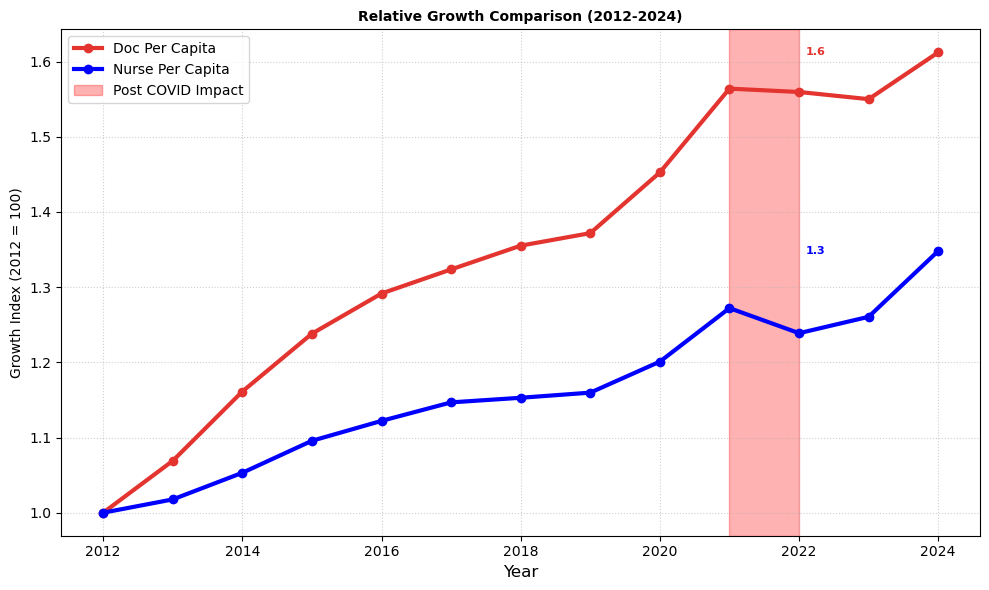

In [35]:
# Per Capita comparison
import matplotlib.pyplot as plt

yoy_df = final[['Year', 'Doc Per Capita', 'Nurse Per Capita']]
yoy_df = yoy_df[yoy_df['Year']<=2024]

yoy_df = yoy_df.set_index('Year')

relative_df = (yoy_df / yoy_df.loc[2012])

fig, ax1 = plt.subplots(figsize=(10, 6))

# Define specific colors and styles to match your image
colors = {'Doc Per Capita': '#e3342f', 
          'Nurse Per Capita': '#0000ff'}

for col in relative_df.columns:
    line, = plt.plot(relative_df.index, relative_df[col], 
                     marker='o', label=col, color=colors[col], linewidth=3)
    
    # Add the final data labels at the end of each line (2022)
    final_val = relative_df[col].iloc[-1]
    plt.text(2022.1, final_val, f'{final_val:.1f}', 
             color=colors[col], fontweight='bold', va='center',fontsize = 8)

# 4. Styling and Labels
plt.title('Relative Growth Comparison (2012-2024)', fontweight='bold', fontsize=10)
ax1.axvspan(2021, 2022, alpha = 0.3, color='red', label='Post COVID Impact')
plt.ylabel('Growth Index (2012 = 100)', fontsize=10)
plt.xlabel('Year', fontsize=12)

# Grid and Ticks
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left')

# Adjust layout to make room for labels on the right
plt.tight_layout()
plt.show()

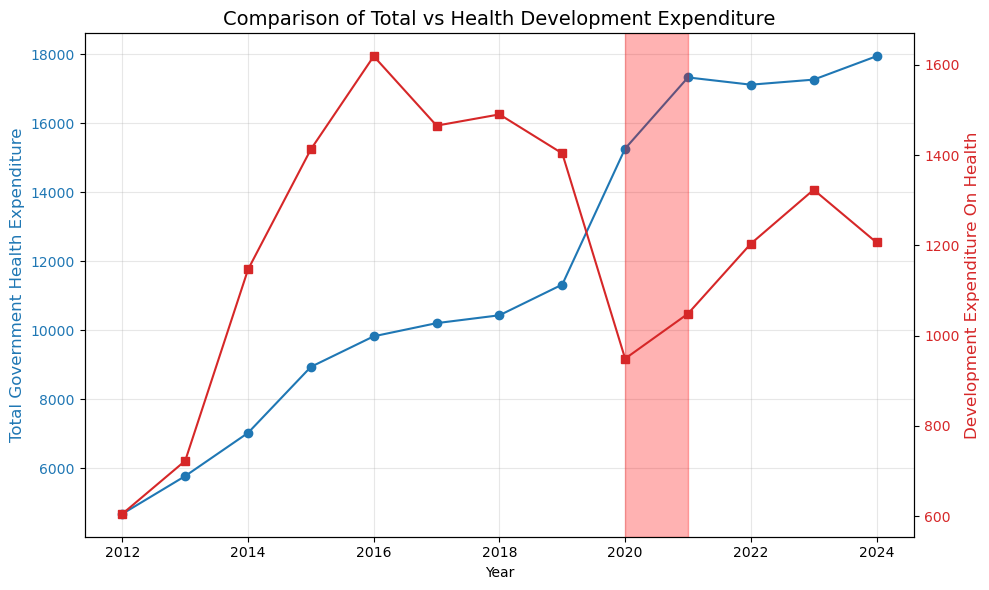

In [36]:
# Total Population vs 
import matplotlib.pyplot as plt

data = final[['Year','Total Government Health Expenditure','Development Expenditure On Health']]
data = data.sort_values(by='Year')

# 1. Create the figure and the first axis (ax1)
fig, ax1 = plt.subplots(figsize=(10, 6))

# 2. Plot the first dataset (65 Years & Over) on ax1
color1 = 'tab:blue'
ax1.set_xlabel('Year')
ax1.set_ylabel('Total Government Health Expenditure', color=color1, fontsize=12)
ax1.plot(data['Year'], data['Total Government Health Expenditure'], color=color1, marker='o', label='Total Population')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid(True, alpha=0.3)

# 3. Create a second axis (ax2) that shares the same x-axis
ax2 = ax1.twinx() 

# 4. Plot the second dataset (Health CPI) on ax2
color2 = 'tab:red'
ax2.set_ylabel('Development Expenditure On Health', color=color2, fontsize=12)
ax2.plot(data['Year'], data['Development Expenditure On Health'], color=color2, marker='s', label='Development Expenditure')
ax2.axvspan(2020, 2021, alpha = 0.3, color='red', label='COVID-19 Period')
ax2.tick_params(axis='y', labelcolor=color2)

# 5. Final touches
plt.title('Comparison of Total vs Health Development Expenditure', fontsize=14)
fig.tight_layout()  # Adjust layout to make room for labels

# Show plot
plt.show()

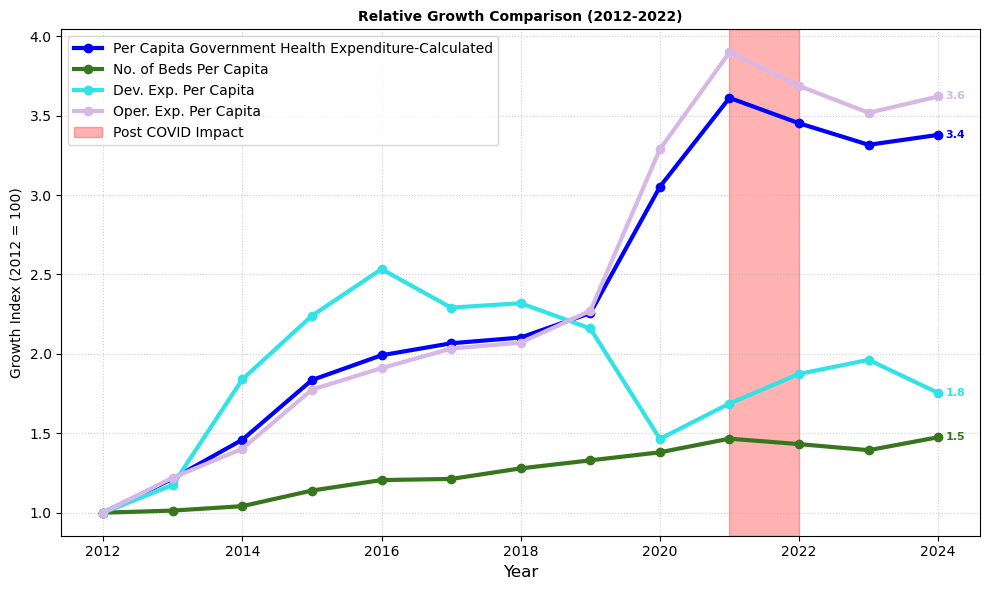

In [37]:
#Relative growth
yoy_df = final[['Year', 'Per Capita Government Health Expenditure-Calculated', 'No. of Beds Per Capita', 'Dev. Exp. Per Capita', 'Oper. Exp. Per Capita']]
yoy_df = yoy_df[yoy_df['Year']<=2024]

yoy_df = yoy_df.set_index('Year')

relative_df = (yoy_df / yoy_df.loc[2012])

fig, ax1 = plt.subplots(figsize=(10, 6))

# Define specific colors and styles to match your image
colors = {'Per Capita Government Health Expenditure-Calculated': '#0000ff', 
          'No. of Beds Per Capita': '#38761d',
          'Dev. Exp. Per Capita': '#32e3e6', 
          'Oper. Exp. Per Capita': '#d7b7e5'}

for col in relative_df.columns:
    line, = plt.plot(relative_df.index, relative_df[col], 
                     marker='o', label=col, color=colors[col], linewidth=3)
    
    # Add the final data labels at the end of each line (2022)
    final_val = relative_df[col].iloc[-1]
    plt.text(2024.1, final_val, f'{final_val:.1f}', 
             color=colors[col], fontweight='bold', va='center',fontsize = 8)

# 4. Styling and Labels
ax1.axvspan(2021, 2022, alpha = 0.3, color='red', label='Post COVID Impact')
plt.title('Relative Growth Comparison (2012-2022)', fontweight='bold', fontsize=10)
plt.ylabel('Growth Index (2012 = 100)', fontsize=10)
plt.xlabel('Year', fontsize=12)

# Grid and Ticks
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left')

# Adjust layout to make room for labels on the right
plt.tight_layout()
plt.show()

# Statistical Analysis
This script performs comprehensive statistical analysis including:
1. Normality tests (Shapiro-Wilk)
2. Hypothesis testing (Mann-Whitney U test, levene, t-test, ANOVA)

# Normality Test

In [38]:
# ── Normality Test (Shapiro-Wilk) ─────────────────────────────────────────
# COVID years excluded: shock-driven values inflate tails and distort distribution shape
from scipy.stats import shapiro

data     = final.copy()
no_covid = data[~data['Year'].isin([2019, 2020])].copy()
normality = {}  # keyed by variable name — used downstream to select test method

test_vars = [
    'Total Population',
    'Per Capita Government Health Expenditure-Calculated',
    'Oper. Exp. Per Capita',
    'Dev. Exp. Per Capita',
    'No. of Beds Per Capita',
    'Doc Per Capita',
    'Nurse Per Capita',
    'Docs per 1000',
    'Nurses per 1000',
    'Beds per 1000',
    'Nurse Doc Ratio',
    'Health Exp % GDP',
]

print(f"{'Variable':<50} {'W-stat':>8} {'p-value':>9}  Result   Test to Use")
print("-" * 85)
for var in test_vars:
    if var in no_covid.columns:
        vals = pd.to_numeric(no_covid[var], errors='coerce').dropna()
        if len(vals) >= 3:
            stat, p_val = shapiro(vals)
            is_normal = p_val > 0.05
            result    = 'Normal'     if is_normal else 'NOT Normal'
            test_use  = 'ANOVA / t-test' if is_normal else 'KW / Mann-Whitney U'
            normality[var] = {'statistic': stat, 'p_value': p_val, 'normal': is_normal}
            marker = '✓' if is_normal else '✗'
            print(f"  {var:<48} {stat:>8.4f}  {p_val:>8.4f}  {marker} {result:<12} {test_use}")

print()
normal_vars     = [v for v, r in normality.items() if     r['normal']]
non_normal_vars = [v for v, r in normality.items() if not r['normal']]
print(f"  Parametric  ({len(normal_vars)}): {normal_vars}")
print(f"  Non-Parametric ({len(non_normal_vars)}): {non_normal_vars}")


Variable                                             W-stat   p-value  Result   Test to Use
-------------------------------------------------------------------------------------
  Total Population                                   0.9141    0.2726  ✓ Normal       ANOVA / t-test
  Per Capita Government Health Expenditure-Calculated   0.8858    0.1232  ✓ Normal       ANOVA / t-test
  Oper. Exp. Per Capita                              0.8655    0.0678  ✓ Normal       ANOVA / t-test
  Dev. Exp. Per Capita                               0.9374    0.4905  ✓ Normal       ANOVA / t-test
  No. of Beds Per Capita                             0.9066    0.2222  ✓ Normal       ANOVA / t-test
  Doc Per Capita                                     0.9261    0.3724  ✓ Normal       ANOVA / t-test
  Nurse Per Capita                                   0.9573    0.7380  ✓ Normal       ANOVA / t-test
  Docs per 1000                                      0.9262    0.3734  ✓ Normal       ANOVA / t-test
  Nurses pe

# Hypothesis Testing

In [39]:
# ── H2: COVID-19 Impact on Per Capita Health Expenditure ──────────────────
# Directional H₁: expenditure was HIGHER during/after COVID than before
from scipy import stats

data = final.copy()
pre_covid    = data[data['Year'] <  2019]
covid_period = data[data['Year'].isin([2019, 2020])]
post_covid   = data[data['Year'] >  2020]

#Non-parametric method used as covid years are driving shock numbers, this method doesn't assume normality distribution
print(" \n A. COVID-19 IMPACT  (Mann-Whitney U — directional, one-tailed)")
print("-" * 60)
print("VARIABLE: Per Capita Government Health Expenditure-Calculated")
print("-" * 60)

pre_data   = pd.to_numeric(pre_covid['Per Capita Government Health Expenditure-Calculated'],   errors='coerce').dropna()
covid_data = pd.to_numeric(covid_period['Per Capita Government Health Expenditure-Calculated'], errors='coerce').dropna()
post_data  = pd.to_numeric(post_covid['Per Capita Government Health Expenditure-Calculated'],  errors='coerce').dropna()

print(f"\n Descriptive Statistics (Median · IQR — non-normal data):")
for label, d in [('Pre-COVID  (<2019)', pre_data),
                  ('COVID      (2019-20)', covid_data),
                  ('Post-COVID (>2020)', post_data)]:
    iqr = d.quantile(0.75) - d.quantile(0.25)
    print(f"   {label} n={len(d)}: Median={d.median():.4f}, IQR={iqr:.4f}")

# Overall Kruskal-Wallis
kw_stat, kw_p = stats.kruskal(pre_data, covid_data, post_data)
print(f"\n Overall Kruskal-Wallis (all 3 periods):")
print(f"   H={kw_stat:.4f}, p={kw_p:.4f}  → {'Reject H₀' if kw_p < 0.05 else 'Fail to reject H₀'}")

# H₁: Pre < COVID (one-tailed: COVID raised expenditure)
print(f"\n HYPOTHESIS TEST 1: Pre-COVID vs COVID")
print(f"   H₀: No difference  |  H₁: COVID expenditure > Pre-COVID")
u, p = stats.mannwhitneyu(pre_data, covid_data, alternative='less')
print(f"   U={u:.4f}, p={p:.4f}  → {'Reject H₀' if p < 0.05 else 'Fail to reject H₀'} (α=0.05)")
if p < 0.05:
    print(f"   Median change: {((covid_data.median()/pre_data.median())-1)*100:+.1f}%")

# H₁: COVID < Post (expenditure stayed elevated)
print(f"\n HYPOTHESIS TEST 2: COVID vs Post-COVID")
print(f"   H₀: No difference  |  H₁: Post-COVID expenditure > COVID")
u, p = stats.mannwhitneyu(covid_data, post_data, alternative='less')
print(f"   U={u:.4f}, p={p:.4f}  → {'Reject H₀' if p < 0.05 else 'Fail to reject H₀'} (α=0.05)")
if p < 0.05:
    print(f"   Median change: {((post_data.median()/covid_data.median())-1)*100:+.1f}%")


 
 A. COVID-19 IMPACT  (Mann-Whitney U — directional, one-tailed)
------------------------------------------------------------
VARIABLE: Per Capita Government Health Expenditure-Calculated
------------------------------------------------------------

 Descriptive Statistics (Median · IQR — non-normal data):
   Pre-COVID  (<2019) n=7: Median=0.0016, IQR=0.0006
   COVID      (2019-20) n=2: Median=0.0023, IQR=0.0003
   Post-COVID (>2020) n=4: Median=0.0030, IQR=0.0001

 Overall Kruskal-Wallis (all 3 periods):
   H=9.7912, p=0.0075  → Reject H₀

 HYPOTHESIS TEST 1: Pre-COVID vs COVID
   H₀: No difference  |  H₁: COVID expenditure > Pre-COVID
   U=0.0000, p=0.0278  → Reject H₀ (α=0.05)
   Median change: +44.6%

 HYPOTHESIS TEST 2: COVID vs Post-COVID
   H₀: No difference  |  H₁: Post-COVID expenditure > COVID
   U=0.0000, p=0.0667  → Fail to reject H₀ (α=0.05)


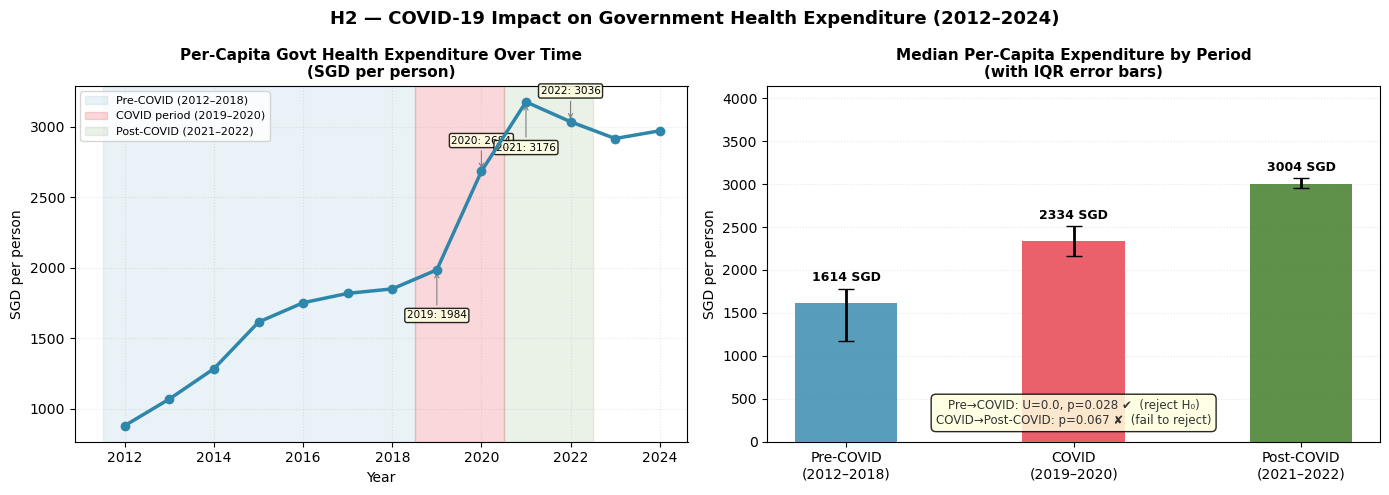

In [40]:
# ── H2 Visualisation ──────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import os; os.makedirs('outputs', exist_ok=True)

data_h2 = final.copy()
pre_covid    = data_h2[data_h2['Year'] < 2019]
covid_period = data_h2[data_h2['Year'].isin([2019, 2020])]
post_covid   = data_h2[data_h2['Year'] > 2020]
pc_var = 'Per Capita Government Health Expenditure-Calculated'

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('H2 — COVID-19 Impact on Government Health Expenditure (2012–2024)',
             fontsize=13, fontweight='bold')

# ── Panel 1: Per-Capita Government Health Expenditure time series ──────────
ax1 = axes[0]
plot_d = data_h2.dropna(subset=[pc_var]).sort_values('Year')
yvals  = pd.to_numeric(plot_d[pc_var], errors='coerce') * 1e6  # SGD per person

ax1.plot(plot_d['Year'], yvals, marker='o', lw=2.5, color='#2E86AB', zorder=5)
ax1.axvspan(2011.5, 2018.5, alpha=0.10, color='#2E86AB', label='Pre-COVID (2012–2018)')
ax1.axvspan(2018.5, 2020.5, alpha=0.20, color='#E63946', label='COVID period (2019–2020)')
ax1.axvspan(2020.5, 2022.5, alpha=0.10, color='#38761D', label='Post-COVID (2021–2022)')

for yr in [2019, 2020, 2021, 2022]:
    row = plot_d[plot_d['Year'] == yr]
    if len(row):
        v = float(row[pc_var].values[0]) * 1e6
        offset = 20 if yr % 2 == 0 else -35
        ax1.annotate(f'{yr}: {v:.0f}', xy=(yr, v), xytext=(0, offset),
                     textcoords='offset points', ha='center', fontsize=7.5,
                     arrowprops=dict(arrowstyle='->', color='grey', lw=0.8),
                     bbox=dict(boxstyle='round,pad=0.2', facecolor='lightyellow', alpha=0.85))

ax1.set_title('Per-Capita Govt Health Expenditure Over Time\n(SGD per person)',
              fontweight='bold', fontsize=11)
ax1.set_xlabel('Year'); ax1.set_ylabel('SGD per person')
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}'))
ax1.grid(True, alpha=0.3, linestyle=':')
ax1.legend(fontsize=8, loc='upper left')

# ── Panel 2: Median comparison across periods ──────────────────────────────
ax2 = axes[1]
period_labels = ['Pre-COVID\n(2012–2018)', 'COVID\n(2019–2020)', 'Post-COVID\n(2021–2022)']
period_dfs    = [pre_covid, covid_period, post_covid]
period_data   = [pd.to_numeric(df[pc_var], errors='coerce').dropna() * 1e6 for df in period_dfs]
medians = [d.median() for d in period_data]
q25     = [d.quantile(0.25) for d in period_data]
q75     = [d.quantile(0.75) for d in period_data]
colors_p = ['#2E86AB', '#E63946', '#38761D']

bars = ax2.bar(period_labels, medians, color=colors_p, alpha=0.8, width=0.45, zorder=3)
for bar, med, lo, hi in zip(bars, medians, q25, q75):
    ax2.errorbar(bar.get_x() + bar.get_width()/2, med,
                 yerr=[[med - lo], [hi - med]],
                 fmt='none', color='black', capsize=6, lw=2, zorder=5)
    ax2.text(bar.get_x() + bar.get_width()/2, hi + 50,
             f'{med:.0f} SGD', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax2.set_title('Median Per-Capita Expenditure by Period\n(with IQR error bars)',
              fontweight='bold', fontsize=11)
ax2.set_ylabel('SGD per person')
ax2.grid(True, axis='y', alpha=0.3, linestyle=':')
ax2.set_ylim(0, max(q75) * 1.35)
ax2.text(0.5, 0.05,
         'Pre→COVID: U=0.0, p=0.028 ✔  (reject H₀)\nCOVID→Post-COVID: p=0.067 ✘  (fail to reject)',
         transform=ax2.transAxes, ha='center', fontsize=8.5, color='#333',
         bbox=dict(boxstyle='round,pad=0.4', facecolor='lightyellow', alpha=0.85))

plt.tight_layout()
plt.savefig('outputs/H2_covid_expenditure_impact.png', dpi=150, bbox_inches='tight')
plt.show()


In [41]:
print("H2 Visual Summary:")
print(f"  Pre-COVID  median: {medians[0]:.0f} SGD/person")
print(f"  COVID      median: {medians[1]:.0f} SGD/person  (+{(medians[1]/medians[0]-1)*100:.1f}%)")
print(f"  Post-COVID median: {medians[2]:.0f} SGD/person  (+{(medians[2]/medians[1]-1)*100:.1f}% vs COVID)")

H2 Visual Summary:
  Pre-COVID  median: 1614 SGD/person
  COVID      median: 2334 SGD/person  (+44.6%)
  Post-COVID median: 3004 SGD/person  (+28.7% vs COVID)


In [42]:
# ── H3: Expenditure Deep Dive ─────────────────────────────────────────────
# RQ: How is government health expenditure growing across time periods,
#     what does the Oper vs Dev composition shift reveal, and is the growing
#     65+ population share a structural driver of operating cost pressure?
from scipy import stats
from scipy.stats import levene, f_oneway, ttest_ind, spearmanr
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os; os.makedirs('outputs', exist_ok=True)

data = final.copy()
data['Period'] = pd.cut(data['Year'],
                        bins=[2011, 2016, 2020, 2024],
                        labels=['Early (2012-2016)', 'Mid (2017-2020)', 'Recent (2021-2024)'])
periods = ['Early (2012-2016)', 'Mid (2017-2020)', 'Recent (2021-2024)']

def period_test(var, grps):
    is_n = normality.get(var,{}).get('normal', True)
    lf,lp = levene(*grps)
    if is_n:
        f,fp = f_oneway(*grps)
        return ('One-Way ANOVA', f, fp, lf, lp, is_n)
    else:
        kh,kp = stats.kruskal(*grps)
        return ('Kruskal-Wallis', kh, kp, lf, lp, is_n)

print("=" * 65)
print(" H3 — EXPENDITURE DEEP DIVE")
print("=" * 65)

# ── PART A: Descriptive ───────────────────────────────────────────────────
print("\n── PART A: Operating vs Development Per Capita ──────────────")
grps_oper, grps_dev = [], []
for var, label, store in [('Oper. Exp. Per Capita','Operating', 'oper'),
                           ('Dev. Exp. Per Capita', 'Development','dev')]:
    print(f"\n  {label} Expenditure Per Capita (SGD):")
    print(f"  {'Period':<24} {'n':>3} {'Mean':>10} {'SD':>10} {'Median':>10}  Δ vs Prior")
    print("  " + "-" * 65)
    prev = None; grps = []
    for pname in periods:
        g = pd.to_numeric(data[data['Period']==pname][var], errors='coerce').dropna()
        grps.append(g)
        chg = f"{((g.median()/prev)-1)*100:+.1f}%" if prev else "baseline"
        print(f"  {pname:<24} {len(g):>3} {g.mean():>10.6f} {g.std():>10.6f} {g.median():>10.6f}  {chg}")
        prev = g.median()
    if store == 'oper': grps_oper = grps
    else:               grps_dev  = grps

print("\n  Development share of total health budget:")
for pname in periods:
    g = data[data['Period']==pname]['Dev Budget Share %'].dropna()
    print(f"    {pname}: avg={g.mean():.1f}%  (min {g.min():.1f}% – max {g.max():.1f}%)")


 H3 — EXPENDITURE DEEP DIVE

── PART A: Operating vs Development Per Capita ──────────────

  Operating Expenditure Per Capita (SGD):
  Period                     n       Mean         SD     Median  Δ vs Prior
  -----------------------------------------------------------------
  Early (2012-2016)          5   0.001119   0.000290   0.001074  baseline
  Mid (2017-2020)            4   0.001849   0.000452   0.001662  +54.8%
  Recent (2021-2024)         4   0.002818   0.000123   0.002797  +68.3%

  Development Expenditure Per Capita (SGD):
  Period                     n       Mean         SD     Median  Δ vs Prior
  -----------------------------------------------------------------
  Early (2012-2016)          5   0.000200   0.000076   0.000210  baseline
  Mid (2017-2020)            4   0.000235   0.000046   0.000254  +21.0%
  Recent (2021-2024)         4   0.000207   0.000014   0.000207  -18.5%

  Development share of total health budget:
    Early (2012-2016): avg=14.8%  (min 12.5% – max 1

/var/folders/w1/cdjvhn651xq1sw_3s_r48cjw0000gp/T/ipykernel_9819/2513787530.py:48: MatplotlibDeprecationWarning: An artist whose label starts with an underscore was passed to legend(); such artists will no longer be ignored in the future.  To suppress this warning, explicitly filter out such artists, e.g. with `[art for art in artists if not art.get_label().startswith('_')]`.
  ax_b.legend(handles=[blue_p, red_p, purp_p, ax_b.lines[1]], fontsize=9, loc='upper left')


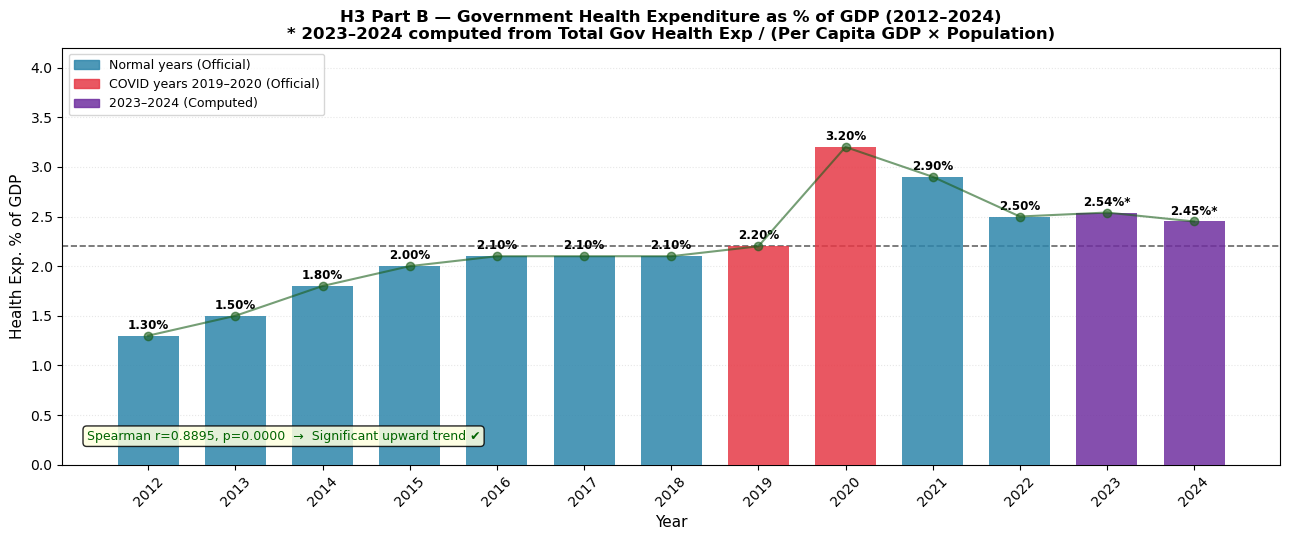

Saved → outputs/H3_partB_health_pct_gdp.png

  Health Exp % GDP values used:
    2012: 1.30% 
    2013: 1.50% 
    2014: 1.80% 
    2015: 2.00% 
    2016: 2.10% 
    2017: 2.10% 
    2018: 2.10% 
    2019: 2.20% 
    2020: 3.20% 
    2021: 2.90% 
    2022: 2.50% 
    2023: 2.54%*
    2024: 2.45%*
  (* = computed from Total Gov Health Exp / (Per Capita GDP × Population))


In [43]:
# ── PART B Plot: Health Expenditure as % of GDP (2012–2024) ──────────────
# 2012-2022: Official government source
# 2023-2024: Computed from Total Gov Health Exp / (Per Capita GDP × Population)
import matplotlib.patches as mpatches
fig_b, ax_b = plt.subplots(figsize=(13, 5.5))

gdp_full = data[['Year','Health Exp % GDP','Health Exp % GDP Source']].dropna(
    subset=['Health Exp % GDP']).sort_values('Year')

bar_cols = []
for _, row in gdp_full.iterrows():
    if row['Year'] in [2019, 2020]:
        bar_cols.append('#E63946')         # COVID years
    elif row['Health Exp % GDP Source'] == 'Computed':
        bar_cols.append('#7030A0')         # estimated 2023/24
    else:
        bar_cols.append('#2E86AB')         # normal official

bars_b = ax_b.bar(gdp_full['Year'], gdp_full['Health Exp % GDP'],
                  color=bar_cols, alpha=0.85, width=0.7, zorder=3)

for bar, (_, row) in zip(bars_b, gdp_full.iterrows()):
    val = row['Health Exp % GDP']
    label = f'{val:.2f}%'
    if row['Health Exp % GDP Source'] == 'Computed':
        label += '*'
    ax_b.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.04,
              label, ha='center', va='bottom', fontsize=8.5, fontweight='bold')

mean_gdp = gdp_full['Health Exp % GDP'].mean()
ax_b.axhline(y=mean_gdp, color='black', ls='--', lw=1.2, alpha=0.6,
             label=f'Period mean = {mean_gdp:.2f}%')
ax_b.plot(gdp_full['Year'], gdp_full['Health Exp % GDP'],
          marker='o', lw=1.5, color='#1A5E1A', zorder=4, alpha=0.6)

ax_b.set_title('H3 Part B — Government Health Expenditure as % of GDP (2012–2024)\n'
               '* 2023–2024 computed from Total Gov Health Exp / (Per Capita GDP × Population)',
               fontweight='bold', fontsize=12)
ax_b.set_xlabel('Year', fontsize=11); ax_b.set_ylabel('Health Exp. % of GDP', fontsize=11)
ax_b.set_ylim(0, 4.2)
ax_b.set_xticks(gdp_full['Year'].astype(int).tolist())
ax_b.tick_params(axis='x', rotation=45)
ax_b.grid(True, axis='y', alpha=0.3, linestyle=':')

blue_p  = mpatches.Patch(color='#2E86AB', alpha=0.85, label='Normal years (Official)')
red_p   = mpatches.Patch(color='#E63946', alpha=0.85, label='COVID years 2019–2020 (Official)')
purp_p  = mpatches.Patch(color='#7030A0', alpha=0.85, label='2023–2024 (Computed)')
ax_b.legend(handles=[blue_p, red_p, purp_p, ax_b.lines[1]], fontsize=9, loc='upper left')

r_g, p_g = spearmanr(gdp_full['Year'].astype(float), gdp_full['Health Exp % GDP'])
ax_b.text(0.02, 0.06,
          f'Spearman r={r_g:.4f}, p={p_g:.4f}  →  Significant upward trend ✔',
          transform=ax_b.transAxes, fontsize=9, color='darkgreen',
          bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.85))

plt.tight_layout()
plt.savefig('outputs/H3_partB_health_pct_gdp.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved → outputs/H3_partB_health_pct_gdp.png")
print()
print("  Health Exp % GDP values used:")
for _, row in gdp_full.iterrows():
    star = '*' if row['Health Exp % GDP Source'] == 'Computed' else ' '
    print(f"    {int(row['Year'])}: {row['Health Exp % GDP']:.2f}%{star}")
print("  (* = computed from Total Gov Health Exp / (Per Capita GDP × Population))")


In [44]:
# ── PART C: CPI sub-components (uses already-loaded `cpi` dataframe) ──────
print("\n── PART C: Health Inflation by Type of Care (2019=100) ───────")
cpi7 = cpi.iloc[:7, :11].set_index('Data Series').T
cpi7.index = cpi7.index.str.strip(); cpi7.columns = cpi7.columns.str.strip()
for c in cpi7.columns: cpi7[c] = pd.to_numeric(cpi7[c], errors='coerce')
cpi7 = cpi7.reset_index().rename(columns={'index':'Year'})
cpi7['Year'] = pd.to_numeric(cpi7['Year'], errors='coerce').astype('Int64')
sub_cols = ['Inpatient Care Services','Outpatient Care Services',
            'Medicines & Health Products','Health Insurance']
for col in sub_cols:
    base_v = cpi7.loc[cpi7['Year']==2019, col].values
    if len(base_v)>0 and not np.isnan(base_v[0]):
        cpi7[col+'_r'] = (cpi7[col] / base_v[0] * 100).round(2)
avail = cpi7.sort_values('Year').dropna(subset=['Inpatient Care Services_r'])
print(f"  {'Year':>6}  {'Inpatient':>10}  {'Outpatient':>11}  {'Medicines':>10}  {'Insurance':>10}")
for _, row in avail.iterrows():
    print(f"  {int(row['Year']):>6}  {row['Inpatient Care Services_r']:>10.2f}  "
          f"{row['Outpatient Care Services_r']:>11.2f}  "
          f"{row['Medicines & Health Products_r']:>10.2f}  "
          f"{row['Health Insurance_r']:>10.2f}")
yr = avail['Year'].astype(float)
for col, short in [('Inpatient Care Services_r','Inpatient'),('Health Insurance_r','Insurance'),
                   ('Outpatient Care Services_r','Outpatient'),('Medicines & Health Products_r','Medicines')]:
    r,p = spearmanr(yr, avail[col])
    print(f"    {short:<20}: r={r:+.4f} {'(p<0.05)' if p<0.05 else '(n.s.)':>8}  "
          f"{'↑ Rising' if r>0.3 else ('→ Flat' if abs(r)<=0.3 else '↓ Falling')}")

# ── PART D: 65+ population composition as Oper/Cap driver ────────────────
print("\n── PART D: 65+ Population as Driver of Operating Expenditure ─")
print("  65+ population sourced from 'Total-65 Years & Over' (pop_transposed)")
print()
print(f"  {'Year':>6}  {'Total Pop (M)':>14}  {'65+ Pop (K)':>12}  {'65+ % Total':>12}  {'Oper/Cap (SGD)':>16}")
print("  " + "-" * 64)
for _, row in data.sort_values('Year').iterrows():
    tp2  = pd.to_numeric(row['Total Population'],  errors='coerce')
    p65  = pd.to_numeric(row['Pop 65+ Total'],     errors='coerce')
    oper = pd.to_numeric(row['Oper. Exp. Per Capita'], errors='coerce')
    pct  = p65/tp2*100 if tp2>0 else np.nan
    print(f"  {int(row['Year']):>6}  {tp2/1e6:>12.3f}M  {p65/1e3:>10.1f}K  {pct:>11.2f}%  {oper:>16.6f}")

print("\n  Growth since 2012 (indexed, 2012=100):")
print(f"  {'Year':>6}  {'Total Pop':>10}  {'65+ Pop':>8}  {'Oper/Cap':>10}")
for _, row in data.sort_values('Year').iterrows():
    print(f"  {int(row['Year']):>6}  {row['Total Pop Index']:>10.1f}  "
          f"{row['Pop65 Index']:>8.1f}  {row['Oper Exp PC Index']:>10.1f}")

# Spearman tests
x65 = data['Aging Ratio']; y_op = data['Oper. Exp. Per Capita']
idx = x65.dropna().index.intersection(y_op.dropna().index)
r_pct, p_pct = spearmanr(x65[idx], y_op[idx])
x65a = data['Pop 65+ Total']; idx2 = x65a.dropna().index.intersection(y_op.dropna().index)
r_abs, p_abs = spearmanr(x65a[idx2], y_op[idx2])
print(f"\n  Spearman: 65+ absolute count → Oper/Capita:  r={r_abs:+.4f}, p={p_abs:.4f}  ✔")
print(f"  Spearman: 65+ % of total pop  → Oper/Capita:  r={r_pct:+.4f}, p={p_pct:.4f}  ✔")
print(f"\n  Key: 65+ pop grew {data['Pop65 Index'].dropna().max():.1f}% vs Total pop {data['Total Pop Index'].max():.1f}%")
print(f"  (2012=100). Operating expenditure grew {data['Oper Exp PC Index'].max():.1f}%.")
print(f"  ► The proportion of elderly residents is strongly associated with")
print(f"    rising per-capita operating costs (r={r_pct:.2f}, p<0.001).")


── PART C: Health Inflation by Type of Care (2019=100) ───────
    Year   Inpatient   Outpatient   Medicines   Insurance
    2015       92.38        93.21      100.35       97.40
    2016       88.82        95.63      100.22       97.90
    2017       93.81        97.54      100.13       99.51
    2018       97.73        99.12      100.38       99.94
    2019      100.00       100.00      100.00      100.00
    2020      100.86        94.18       99.43       99.96
    2021      103.05        93.28       99.61      105.23
    2022      104.28        93.74      101.13      106.55
    2023      101.38        93.82      103.55      108.45
    2024      107.20        97.73      105.77      110.60
    Inpatient           : r=+0.9515 (p<0.05)  ↑ Rising
    Insurance           : r=+0.9879 (p<0.05)  ↑ Rising
    Outpatient          : r=+0.0182   (n.s.)  → Flat
    Medicines           : r=+0.4061   (n.s.)  ↑ Rising

── PART D: 65+ Population as Driver of Operating Expenditure ─
  65+ population

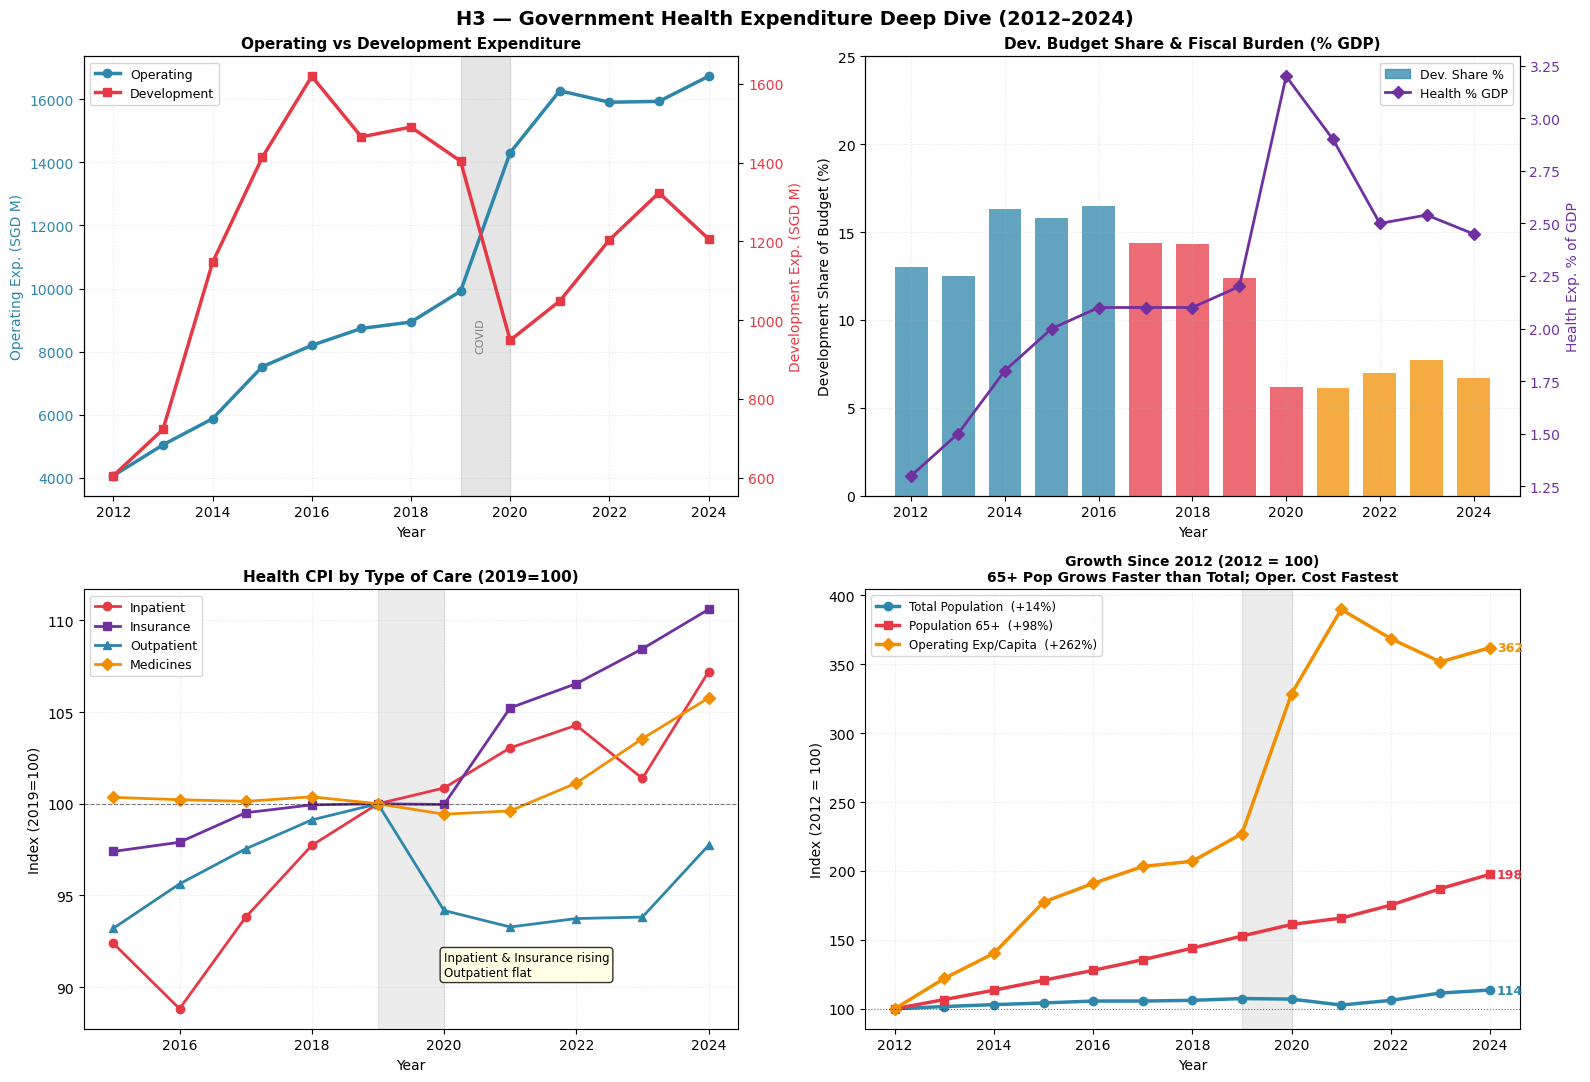

In [45]:
# ── H3 Visualisation ──────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import os; os.makedirs('outputs', exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle('H3 — Government Health Expenditure Deep Dive (2012–2024)',
             fontsize=14, fontweight='bold')
d = final.sort_values('Year').copy()

# ── Panel (0,0): Operating vs Development absolute ────────────────────────
ax1 = axes[0,0]; ax1b = ax1.twinx()
oper_v = pd.to_numeric(d['Operating Expenditure On Health'], errors='coerce')
dev_v  = pd.to_numeric(d['Development Expenditure On Health'], errors='coerce')
ln1, = ax1.plot(d['Year'], oper_v, marker='o', lw=2.5, color='#2E86AB', label='Operating')
ax1.set_ylabel('Operating Exp. (SGD M)', color='#2E86AB', fontsize=10)
ax1.tick_params(axis='y', labelcolor='#2E86AB')
ln2, = ax1b.plot(d['Year'], dev_v, marker='s', lw=2.5, color='#E63946', label='Development')
ax1b.set_ylabel('Development Exp. (SGD M)', color='#E63946', fontsize=10)
ax1b.tick_params(axis='y', labelcolor='#E63946')
ax1.axvspan(2019, 2020, alpha=0.2, color='grey')
ax1.text(2019.3, oper_v.max()*0.48, 'COVID', color='grey', fontsize=8, rotation=90)
ax1.set_title('Operating vs Development Expenditure', fontweight='bold', fontsize=11)
ax1.set_xlabel('Year')
ax1.legend([ln1, ln2], ['Operating', 'Development'], loc='upper left', fontsize=9)
ax1.grid(True, alpha=0.3, linestyle=':')

# ── Panel (0,1): Dev budget share + Health % GDP ──────────────────────────
ax2 = axes[0,1]; ax2b = ax2.twinx()
dev_share = pd.to_numeric(d['Dev Budget Share %'], errors='coerce')
bar_c = ['#2E86AB' if y<=2016 else ('#E63946' if y<=2020 else '#F18F01') for y in d['Year']]
ax2.bar(d['Year'], dev_share, color=bar_c, alpha=0.75, width=0.7)
ax2.set_ylabel('Development Share of Budget (%)', fontsize=10); ax2.set_ylim(0, 25)
gdp_s = d[['Year','Health Exp % GDP']].dropna()
ax2b.plot(gdp_s['Year'], gdp_s['Health Exp % GDP'], marker='D', lw=2, color='#7030A0', zorder=5)
ax2b.set_ylabel('Health Exp. % of GDP', color='#7030A0', fontsize=10)
ax2b.tick_params(axis='y', labelcolor='#7030A0')
ax2.set_title('Dev. Budget Share & Fiscal Burden (% GDP)', fontweight='bold', fontsize=11)
ax2.set_xlabel('Year'); ax2.grid(True, alpha=0.3, linestyle=':')
handles2 = [plt.Rectangle((0,0),1,1,color='#2E86AB',alpha=0.75),
            plt.Line2D([0],[0], color='#7030A0', marker='D', lw=2)]
ax2.legend(handles2, ['Dev. Share %', 'Health % GDP'], loc='upper right', fontsize=9)

# ── Panel (1,0): CPI sub-components (uses already-loaded `cpi` df) ────────
ax3 = axes[1,0]
cpi7 = cpi.iloc[:7,:11].set_index('Data Series').T
cpi7.index=cpi7.index.str.strip(); cpi7.columns=cpi7.columns.str.strip()
for c in cpi7.columns: cpi7[c] = pd.to_numeric(cpi7[c], errors='coerce')
cpi7 = cpi7.reset_index().rename(columns={'index':'Year'})
cpi7['Year'] = pd.to_numeric(cpi7['Year'], errors='coerce').astype('Int64')
for col in ['Inpatient Care Services','Outpatient Care Services',
            'Medicines & Health Products','Health Insurance']:
    base_v = cpi7.loc[cpi7['Year']==2019, col].values
    if len(base_v)>0 and not np.isnan(base_v[0]):
        cpi7[col+'_r'] = (cpi7[col]/base_v[0]*100).round(2)
cpi_plot = cpi7.sort_values('Year').dropna(subset=['Inpatient Care Services_r'])
for col, color, lbl, mk in [
        ('Inpatient Care Services_r',    '#E63946','Inpatient','o'),
        ('Health Insurance_r',           '#7030A0','Insurance','s'),
        ('Outpatient Care Services_r',   '#2E86AB','Outpatient','^'),
        ('Medicines & Health Products_r','#F18F01','Medicines','D')]:
    ax3.plot(cpi_plot['Year'], cpi_plot[col], marker=mk, lw=2, color=color, label=lbl)
ax3.axhline(100, color='black', lw=0.8, ls='--', alpha=0.5)
ax3.axvspan(2019, 2020, alpha=0.15, color='grey')
ax3.set_title('Health CPI by Type of Care (2019=100)', fontweight='bold', fontsize=11)
ax3.set_ylabel('Index (2019=100)'); ax3.set_xlabel('Year')
ax3.legend(fontsize=9, loc='upper left'); ax3.grid(True, alpha=0.3, linestyle=':')
ax3.text(0.55, 0.12, 'Inpatient & Insurance rising\nOutpatient flat',
         transform=ax3.transAxes, fontsize=8.5,
         bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.8))

# ── Panel (1,1): Indexed Growth — Total Pop vs 65+ Pop vs Oper/Cap ────────
ax4 = axes[1,1]
idx_data = d[['Year','Total Pop Index','Pop65 Index','Oper Exp PC Index']].dropna()
ax4.plot(idx_data['Year'], idx_data['Total Pop Index'],  marker='o', lw=2.5,
         color='#2E86AB', label=f"Total Population  (+{idx_data['Total Pop Index'].iloc[-1]-100:.0f}%)")
ax4.plot(idx_data['Year'], idx_data['Pop65 Index'],      marker='s', lw=2.5,
         color='#E63946', label=f"Population 65+  (+{idx_data['Pop65 Index'].iloc[-1]-100:.0f}%)")
ax4.plot(idx_data['Year'], idx_data['Oper Exp PC Index'],marker='D', lw=2.5,
         color='#F18F01', label=f"Operating Exp/Capita  (+{idx_data['Oper Exp PC Index'].iloc[-1]-100:.0f}%)")
ax4.axhline(100, color='black', lw=0.8, ls=':', alpha=0.5)
ax4.axvspan(2019, 2020, alpha=0.15, color='grey')
for col, color in [('Total Pop Index','#2E86AB'),('Pop65 Index','#E63946'),('Oper Exp PC Index','#F18F01')]:
    val = idx_data[col].iloc[-1]
    ax4.annotate(f"{val:.0f}", xy=(idx_data['Year'].iloc[-1], val),
                 xytext=(5, 0), textcoords='offset points', color=color,
                 fontweight='bold', fontsize=9, va='center')
ax4.set_title("Growth Since 2012 (2012 = 100)\n65+ Pop Grows Faster than Total; Oper. Cost Fastest",
              fontweight='bold', fontsize=10)
ax4.set_ylabel('Index (2012 = 100)'); ax4.set_xlabel('Year')
ax4.legend(fontsize=8.5, loc='upper left'); ax4.grid(True, alpha=0.3, linestyle=':')

plt.tight_layout()
plt.savefig('outputs/H3_expenditure_deepdive.png', dpi=150, bbox_inches='tight')
plt.show()


In [46]:
print("Panel (1,1) Key Insight:")
print(f"  Total Population grew +{float(idx_data['Total Pop Index'].iloc[-1])-100:.0f}% since 2012")
print(f"  65+ Population grew    +{float(idx_data['Pop65 Index'].iloc[-1])-100:.0f}% since 2012  (nearly 2× faster)")
print(f"  Operating Exp/Capita grew +{float(idx_data['Oper Exp PC Index'].iloc[-1])-100:.0f}% since 2012 (3.6× faster)")

Panel (1,1) Key Insight:
  Total Population grew +14% since 2012
  65+ Population grew    +98% since 2012  (nearly 2× faster)
  Operating Exp/Capita grew +262% since 2012 (3.6× faster)


In [47]:
# ── H3 Inferential Tests ──────────────────────────────────────────────────
from scipy import stats
from scipy.stats import levene, f_oneway, ttest_ind, spearmanr

print("── H3 Inferential: Operating Expenditure Per Capita ─────────")
is_n_o = normality.get('Oper. Exp. Per Capita',{}).get('normal', True)
lf_o, lp_o = levene(*grps_oper)
f_o,  fp_o  = f_oneway(*grps_oper)
print(f"  Shapiro-Wilk → {'Normal ✓' if is_n_o else 'NOT Normal ✗'}")
print(f"  Levene's: F={lf_o:.4f}, p={lp_o:.4f} → {'Equal variances ✓' if lp_o>0.05 else 'Unequal'}")
print(f"  One-Way ANOVA: F={f_o:.4f}, p={fp_o:.6f} → {'✔ Reject H₀' if fp_o<0.05 else '✘ Fail'}")
print("  Post-hoc t-test (one-tailed H₁: earlier < later):")
for ai, bi, a_s, b_s in [(0,1,'Early','Mid'),(1,2,'Mid','Recent'),(0,2,'Early','Recent')]:
    t, pt = ttest_ind(grps_oper[ai], grps_oper[bi])
    p1 = pt/2 if t < 0 else 1 - pt/2
    chg = (grps_oper[bi].median()/grps_oper[ai].median()-1)*100
    print(f"    {'✔' if p1<0.05 else '✘'} {a_s}→{b_s}: t={t:.4f}, p={p1:.4f} (one-tail), Δmedian={chg:+.1f}%")

print("\n── H3 Inferential: Development Expenditure Per Capita ───────")
is_n_d = normality.get('Dev. Exp. Per Capita',{}).get('normal', True)
lf_d, lp_d = levene(*grps_dev)
f_d,  fp_d  = f_oneway(*grps_dev)
print(f"  Shapiro-Wilk → {'Normal ✓' if is_n_d else 'NOT Normal ✗'}")
print(f"  Levene's: F={lf_d:.4f}, p={lp_d:.4f} → {'Equal variances ✓' if lp_d>0.05 else 'Unequal'}")
print(f"  One-Way ANOVA: F={f_d:.4f}, p={fp_d:.6f} → {'✔ Reject H₀' if fp_d<0.05 else '✘ Fail to reject H₀'}")
print(f"  ► Dev. budget share: "
      f"{data[data['Period']=='Early (2012-2016)']['Dev Budget Share %'].mean():.1f}% (Early) → "
      f"{data[data['Period']=='Recent (2021-2024)']['Dev Budget Share %'].mean():.1f}% (Recent)")

print("\n── H3 Part D: Spearman — 65+ Population → Oper/Capita ──────")
x65 = pd.to_numeric(data['Aging Ratio'], errors='coerce')
y_op = pd.to_numeric(data['Oper. Exp. Per Capita'], errors='coerce')
idx = x65.dropna().index.intersection(y_op.dropna().index)
r_pct, p_pct = spearmanr(x65[idx], y_op[idx])
x65a = pd.to_numeric(data['Pop 65+ Total'], errors='coerce')
idx2 = x65a.dropna().index.intersection(y_op.dropna().index)
r_abs, p_abs = spearmanr(x65a[idx2], y_op[idx2])
print(f"  65+ absolute count → Oper/Capita: r={r_abs:+.4f}, p={p_abs:.4f} ✔")
print(f"  65+ % of total pop → Oper/Capita: r={r_pct:+.4f}, p={p_pct:.4f} ✔")
print(f"  ► 65+ pop grew +{data['Pop65 Index'].dropna().max()-100:.0f}% vs Total pop +{data['Total Pop Index'].max()-100:.0f}% (2012=100)")
print(f"    Operating Exp/Capita grew +{data['Oper Exp PC Index'].max()-100:.0f}%")


── H3 Inferential: Operating Expenditure Per Capita ─────────
  Shapiro-Wilk → Normal ✓
  Levene's: F=0.7179, p=0.5113 → Equal variances ✓
  One-Way ANOVA: F=32.2171, p=0.000044 → ✔ Reject H₀
  Post-hoc t-test (one-tailed H₁: earlier < later):
    ✔ Early→Mid: t=-2.9550, p=0.0106 (one-tail), Δmedian=+54.8%
    ✔ Mid→Recent: t=-4.1325, p=0.0031 (one-tail), Δmedian=+68.3%
    ✔ Early→Recent: t=-10.8421, p=0.0000 (one-tail), Δmedian=+160.5%

── H3 Inferential: Development Expenditure Per Capita ───────
  Shapiro-Wilk → Normal ✓
  Levene's: F=2.5999, p=0.1233 → Equal variances ✓
  One-Way ANOVA: F=0.4720, p=0.636948 → ✘ Fail to reject H₀
  ► Dev. budget share: 14.8% (Early) → 6.9% (Recent)

── H3 Part D: Spearman — 65+ Population → Oper/Capita ──────
  65+ absolute count → Oper/Capita: r=+0.9505, p=0.0000 ✔
  65+ % of total pop → Oper/Capita: r=+0.9505, p=0.0000 ✔
  ► 65+ pop grew +98% vs Total pop +14% (2012=100)
    Operating Exp/Capita grew +290%


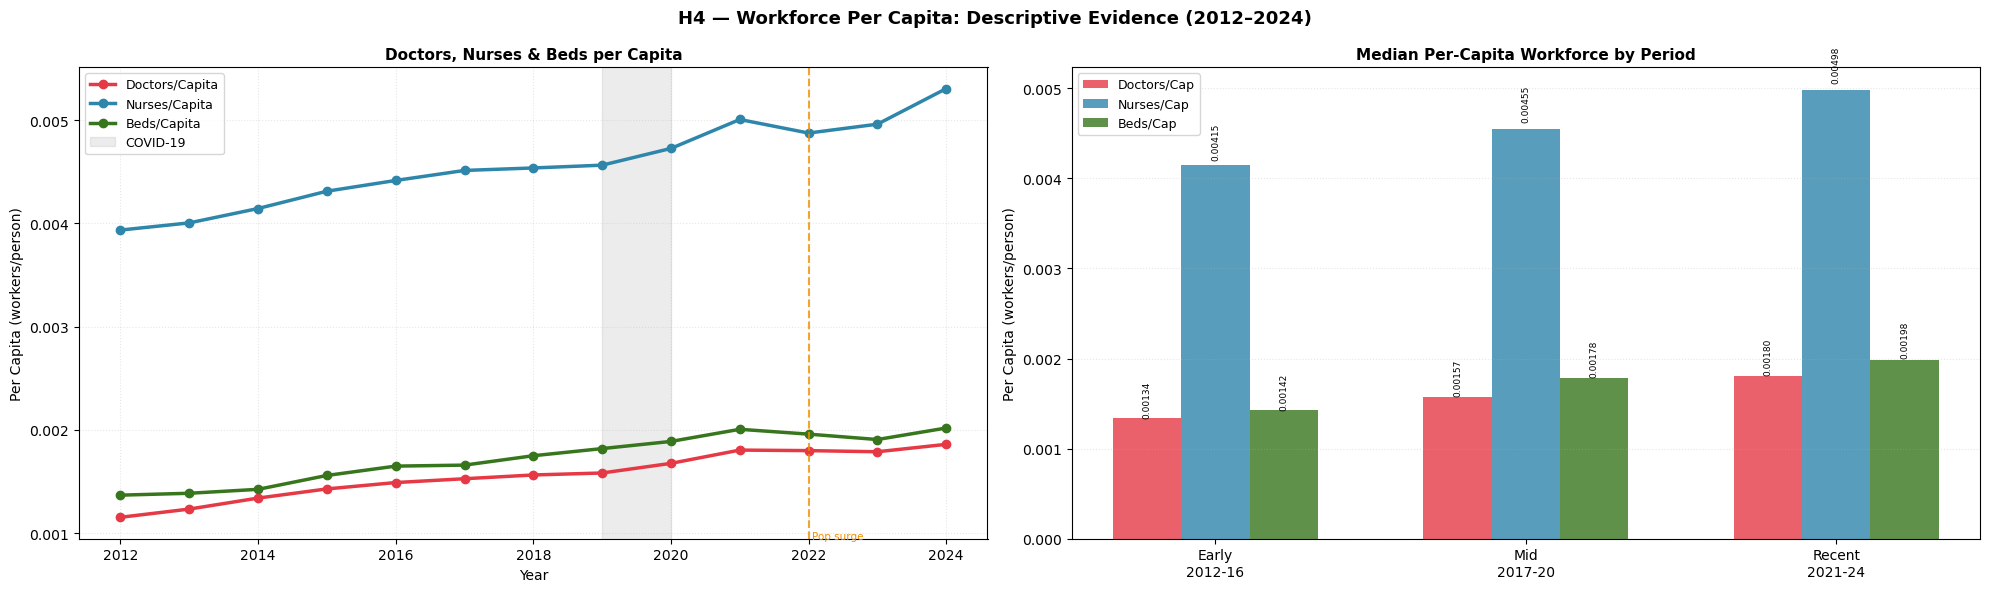

In [57]:
# ── H4 Descriptive Visualisation — Evidence Before Hypothesis Test ────────
import matplotlib.pyplot as plt
import numpy as np
import os; os.makedirs('outputs', exist_ok=True)

d = final.sort_values('Year').copy()
fig, axes = plt.subplots(1, 2, figsize=(20, 6))
fig.suptitle('H4 — Workforce Per Capita: Descriptive Evidence (2012–2024)',
             fontsize=13, fontweight='bold')

# ── Panel (0,0): Per Capita trend lines ───────────────────────────────────
ax = axes[0]
for col, color, lbl in [('Doc Per Capita',        '#E63946', 'Doctors/Capita'),
                          ('Nurse Per Capita',      '#2E86AB', 'Nurses/Capita'),
                          ('No. of Beds Per Capita','#38761D', 'Beds/Capita')]:
    ax.plot(d['Year'], pd.to_numeric(d[col], errors='coerce'),
            marker='o', lw=2.5, color=color, label=lbl)
ax.axvspan(2019, 2020, alpha=0.15, color='grey', label='COVID-19')
ax.axvline(x=2022, color='#F18F01', lw=1.5, ls='--', alpha=0.8)
ax.text(2022.05, ax.get_ylim()[0] if ax.get_ylim()[0]>0 else 0.0015,
        'Pop surge', fontsize=7.5, color='#F18F01')
ax.set_title('Doctors, Nurses & Beds per Capita', fontweight='bold', fontsize=11)
ax.set_xlabel('Year'); ax.set_ylabel('Per Capita (workers/person)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3, linestyle=':')

# ── Panel (0,1): Period medians — grouped bar chart (Per Capita) ──────────
ax2 = axes[1]
wf_pc = [('Doc Per Capita',        'Doctors/Cap', '#E63946'),
         ('Nurse Per Capita',      'Nurses/Cap',  '#2E86AB'),
         ('No. of Beds Per Capita','Beds/Cap',    '#38761D')]
periods_3 = ['Early (2012-2016)', 'Mid (2017-2020)', 'Recent (2021-2024)']
x_pos = np.arange(3); width = 0.22
d_period = final.copy()
d_period['Period'] = pd.cut(d_period['Year'], bins=[2011,2016,2020,2024],
                             labels=periods_3)
for i, (var, lbl, color) in enumerate(wf_pc):
    meds = [d_period[d_period['Period']==p][var].dropna().median() for p in periods_3]
    bars_ = ax2.bar(x_pos + i*width, meds, width, color=color, alpha=0.8, label=lbl)
    for bar, v in zip(bars_, meds):
        ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()*1.02,
                 f'{v:.5f}', ha='center', fontsize=6.5, rotation=90)
ax2.set_xticks(x_pos + width)
ax2.set_xticklabels(['Early\n2012-16', 'Mid\n2017-20', 'Recent\n2021-24'], fontsize=10)
ax2.set_title('Median Per-Capita Workforce by Period', fontweight='bold', fontsize=11)
ax2.set_ylabel('Per Capita (workers/person)'); ax2.legend(fontsize=9)
ax2.grid(True, axis='y', alpha=0.3, linestyle=':')

plt.tight_layout()
plt.show()


In [58]:
# ── H4: Workforce Scaling vs Operating Expenditure Growth ─────────────────
from scipy import stats
from scipy.stats import levene, f_oneway, ttest_ind, shapiro, spearmanr
import numpy as np

data = final.copy()
data['Period'] = pd.cut(data['Year'],
                        bins=[2011, 2016, 2020, 2024],
                        labels=['Early (2012-2016)', 'Mid (2017-2020)', 'Recent (2021-2024)'])
periods = ['Early (2012-2016)', 'Mid (2017-2020)', 'Recent (2021-2024)']

# per Capita variables for hypothesis testing
wf_pc   = [('Doc Per Capita','Doctors/Cap'),('Nurse Per Capita','Nurses/Cap'),('No. of Beds Per Capita','Beds/Cap')]

print("=" * 65)
print(" H4 — WORKFORCE SCALING vs OPERATING EXPENDITURE GROWTH")
print("=" * 65)

# ── PART A: Single combined table — /1000 population ─────────────────────
print("\n── PART A: Workforce per 1,000 Population (readability table) ─")
print(f"  {'Year':>6}  {'Docs/1000':>10}  {'Nurses/1000':>12}  {'Beds/1000':>10}  {'Nurse:Doc':>9}")
print("  " + "─" * 50)
for _, row in data.sort_values('Year').iterrows():
    print(f"  {int(row['Year']):>6}  {row['Docs per 1000']:>10.3f}  "
          f"{row['Nurses per 1000']:>12.3f}  {row['Beds per 1000']:>10.3f}  "
          f"{row['Nurse Doc Ratio']:>9.3f}")

print("\n  Period medians (per Capita — used for hypothesis testing):")
grps_pc = {}
for var, lbl in wf_pc:
    print(f"\n  {lbl}:")
    prev = None; grps = []
    for pname in periods:
        g = pd.to_numeric(data[data['Period']==pname][var], errors='coerce').dropna()
        grps.append(g)
        chg = f"  ({((g.median()/prev)-1)*100:+.1f}%)" if prev else "  (baseline)"
        print(f"    {pname}: n={len(g)}, median={g.median():.6f}{chg}")
        prev = g.median()
    grps_pc[var] = grps

# ── PART B: Normality on FULL data, ANOVA, post-hoc ──────────────────────
print("\n── PART B: Normality (Shapiro-Wilk on full dataset, n=13) ───")
print("  Using full data (not just COVID-excluded) since H4 tests overall trend.")
for var, lbl in wf_pc:
    v = pd.to_numeric(data[var], errors='coerce').dropna()
    w, p = shapiro(v)
    test = 'ANOVA + t-test' if p > 0.05 else 'KW + Mann-Whitney U'
    print(f"    {lbl:<20}: W={w:.4f}, p={p:.4f}  → {'Normal ✓' if p>0.05 else 'NOT Normal ✗'}  → {test}")

print("\n  H₀: Per-Capita workforce is equal across all three time periods")
print("  H₁: Per-Capita workforce increases across periods (directional)")
print()
for var, lbl in wf_pc:
    grps = grps_pc[var]
    v_full = pd.to_numeric(data[var], errors='coerce').dropna()
    is_n = shapiro(v_full)[1] > 0.05
    lf, lp = levene(*grps)
    f_stat, f_p = f_oneway(*grps)
    print(f"  {lbl}:")
    print(f"    Levene's F={lf:.4f}, p={lp:.4f} → {'Equal variances ✓' if lp>0.05 else 'Unequal'}")
    print(f"    One-Way ANOVA: F={f_stat:.4f}, p={f_p:.6f} → {'✔ Reject H₀' if f_p<0.05 else '✘ Fail'}")
    print(f"    Post-hoc t-test (one-tailed H₁: earlier < later — increasing trend):")
    for ai, bi, a_s, b_s in [(0,1,'Early','Mid'),(1,2,'Mid','Recent'),(0,2,'Early','Recent')]:
        t, pt = ttest_ind(grps[ai], grps[bi])
        p1 = pt/2 if t < 0 else 1 - pt/2   # one-tail: earlier < later
        chg = (grps[bi].median()/grps[ai].median()-1)*100
        print(f"      {'✔' if p1<0.05 else '✘'} {a_s}→{b_s}: t={t:.4f}, p={p1:.4f}, Δmedian={chg:+.1f}%")
    print()

# ── PART C: Spearman — Operating Expenditure → Per Capita workforce ───────
print("── PART C: Spearman — Oper. Exp./Capita → Workforce/Capita ───")
print("  H₀: No monotonic relationship | H₁: Higher Oper/Cap → more workforce/capita")
for var, lbl in wf_pc:
    x = pd.to_numeric(data['Oper. Exp. Per Capita'], errors='coerce')
    y = pd.to_numeric(data[var], errors='coerce')
    idx = x.dropna().index.intersection(y.dropna().index)
    r, p = spearmanr(x[idx], y[idx])
    print(f"  Oper/Cap ↔ {lbl:<20}: r={r:+.4f}, p={p:.4f}  ['Very Strong' if {abs(r):.2f}>0.9]")


 H4 — WORKFORCE SCALING vs OPERATING EXPENDITURE GROWTH

── PART A: Workforce per 1,000 Population (readability table) ─
    Year   Docs/1000   Nurses/1000   Beds/1000  Nurse:Doc
  ──────────────────────────────────────────────────
    2012       1.154         3.936       1.368      3.411
    2013       1.234         4.006       1.387      3.247
    2014       1.340         4.145       1.425      3.093
    2015       1.429         4.313       1.559      3.018
    2016       1.491         4.417       1.650      2.963
    2017       1.528         4.514       1.659      2.955
    2018       1.564         4.538       1.750      2.901
    2019       1.583         4.565       1.820      2.883
    2020       1.676         4.727       1.889      2.820
    2021       1.805         5.007       2.006      2.774
    2022       1.800         4.876       1.960      2.709
    2023       1.789         4.962       1.907      2.774
    2024       1.861         5.307       2.019      2.852

  Period medi

In [59]:
# ── PART D: Nurse-to-Doctor Ratio — Hypothesis Test ──────────────────────
print("\n── PART D: Nurse:Doctor Ratio — Is the Mix Shifting? ─────────")
print("  H₀: Nurse:Doctor ratio is equal across time periods")
print("  H₁: Nurse:Doctor ratio is DECLINING across periods (doctors added faster)")
print()
ndr_full = pd.to_numeric(data['Nurse Doc Ratio'], errors='coerce').dropna()
w_ndr, p_ndr = shapiro(ndr_full)
print(f"  Shapiro-Wilk (full data, n={len(ndr_full)}): W={w_ndr:.4f}, p={p_ndr:.4f} → {'Normal ✓' if p_ndr>0.05 else 'NOT Normal ✗'}")
grps_ndr = [pd.to_numeric(data[data['Period']==p]['Nurse Doc Ratio'],errors='coerce').dropna() for p in periods]
lf_n,lp_n = levene(*grps_ndr)
f_n, fp_n  = f_oneway(*grps_ndr)
print(f"  Levene's F={lf_n:.4f}, p={lp_n:.4f} → {'Equal variances ✓' if lp_n>0.05 else 'Unequal'}")
print(f"  One-Way ANOVA: F={f_n:.4f}, p={fp_n:.6f} → {'✔ Reject H₀' if fp_n<0.05 else '✘'}")
print("  Post-hoc t-test (one-tailed H₁: earlier > later — declining trend):")
for ai, bi, a_s, b_s in [(0,1,'Early','Mid'),(1,2,'Mid','Recent'),(0,2,'Early','Recent')]:
    t, pt = ttest_ind(grps_ndr[ai], grps_ndr[bi])
    # For declining: H₁ = earlier > later → significant when t > 0, one-tail p = pt/2
    p1 = pt/2 if t > 0 else 1 - pt/2
    chg = (grps_ndr[bi].median()/grps_ndr[ai].median()-1)*100
    print(f"    {'✔' if p1<0.05 else '✘'} {a_s}→{b_s}: t={t:.4f}, p={p1:.4f} (one-tail), Δmedian={chg:+.1f}%")

print()
r_yr, p_yr   = spearmanr(data['Year'], data['Nurse Doc Ratio'].dropna())
r_pop, p_pop = spearmanr(pd.to_numeric(data['Total Population'],errors='coerce').dropna(),
                          data.loc[pd.to_numeric(data['Total Population'],errors='coerce').dropna().index,'Nurse Doc Ratio'])
print(f"  Spearman Year ↔ N:D Ratio:     r={r_yr:+.4f}, p={p_yr:.4f} ✔ Significant")
print(f"  Spearman Population ↔ N:D Ratio: r={r_pop:+.4f}, p={p_pop:.4f} ✔ Significant")
print(f"\n  Ratio declined: {ndr_full.iloc[0]:.2f} (2012) → {ndr_full.iloc[-1]:.2f} (2024)")
print(f"  Doctors added proportionally faster than nurses relative to total population.")


── PART D: Nurse:Doctor Ratio — Is the Mix Shifting? ─────────
  H₀: Nurse:Doctor ratio is equal across time periods
  H₁: Nurse:Doctor ratio is DECLINING across periods (doctors added faster)

  Shapiro-Wilk (full data, n=13): W=0.9097, p=0.1815 → Normal ✓
  Levene's F=2.3155, p=0.1491 → Equal variances ✓
  One-Way ANOVA: F=10.6952, p=0.003281 → ✔ Reject H₀
  Post-hoc t-test (one-tailed H₁: earlier > later — declining trend):
    ✔ Early→Mid: t=2.6824, p=0.0157 (one-tail), Δmedian=-6.5%
    ✔ Mid→Recent: t=2.7864, p=0.0159 (one-tail), Δmedian=-4.1%
    ✔ Early→Recent: t=3.8451, p=0.0032 (one-tail), Δmedian=-10.3%

  Spearman Year ↔ N:D Ratio:     r=-0.9354, p=0.0000 ✔ Significant
  Spearman Population ↔ N:D Ratio: r=-0.6410, p=0.0182 ✔ Significant

  Ratio declined: 3.41 (2012) → 2.85 (2024)
  Doctors added proportionally faster than nurses relative to total population.


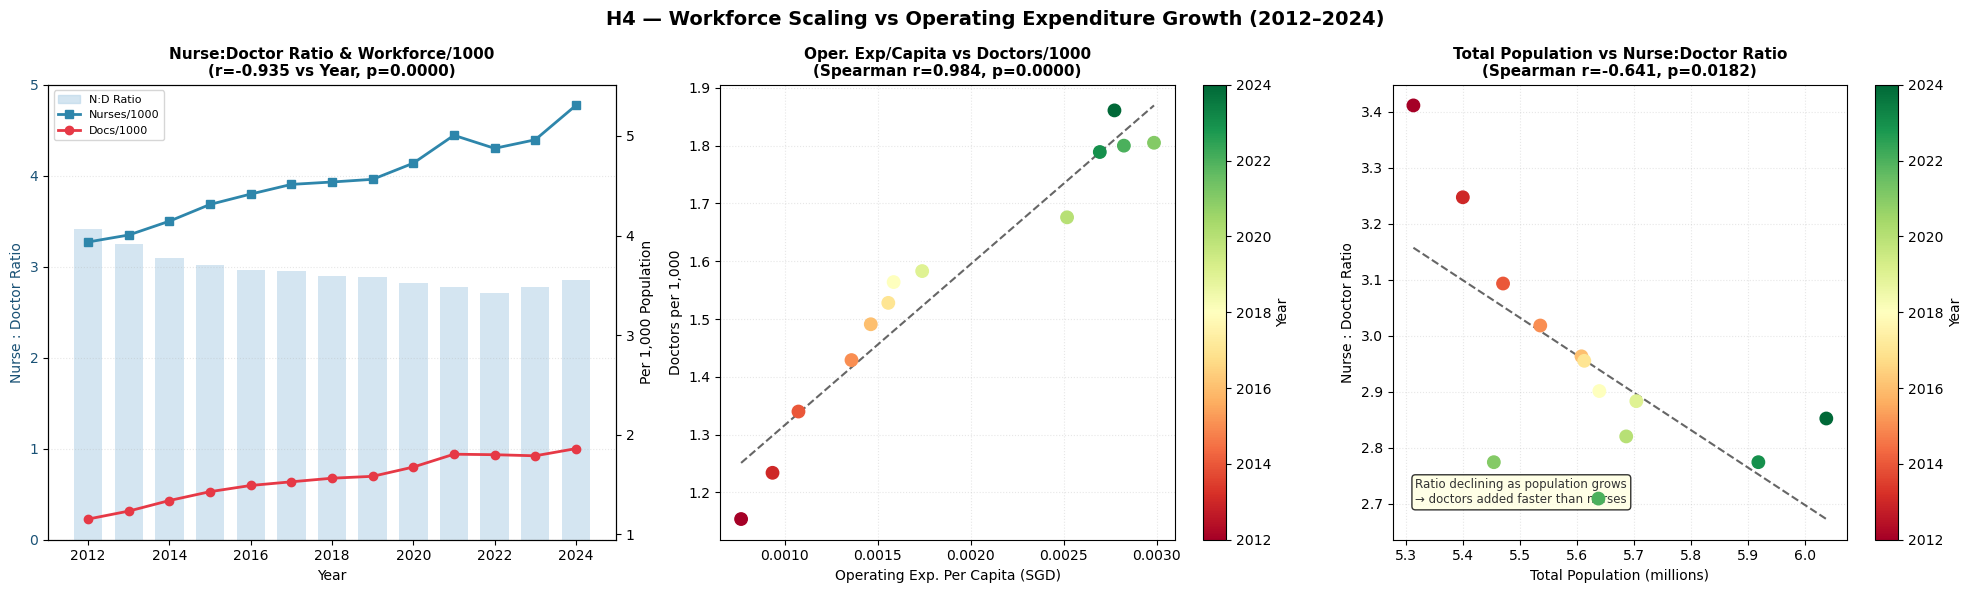

In [63]:
# ── H4 Visualisation ──────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import spearmanr
import os; os.makedirs('outputs', exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('H4 — Workforce Scaling vs Operating Expenditure Growth (2012–2024)',
             fontsize=14, fontweight='bold')

d = final.sort_values('Year').copy()

# ── Row 2, col 0: Nurse:Doctor ratio per population trend ────────────────
ax = axes[0]
ndr = d.dropna(subset=['Nurse Doc Ratio','Nurses per 1000','Docs per 1000'])
color_n, color_d = '#2E86AB', '#E63946'
ax_r = ax.twinx()
ax.bar(ndr['Year'], ndr['Nurse Doc Ratio'], color='#B8D4E8', alpha=0.6,
       width=0.7, label='N:D Ratio (left)')
ax.set_ylabel('Nurse : Doctor Ratio', color='#1A5276', fontsize=10)
ax.tick_params(axis='y', labelcolor='#1A5276')
ax.set_ylim(0, 5)
ln1, = ax_r.plot(ndr['Year'], ndr['Nurses per 1000'], marker='s', lw=2,
                  color=color_n, label='Nurses/1000')
ln2, = ax_r.plot(ndr['Year'], ndr['Docs per 1000'],   marker='o', lw=2,
                  color=color_d, label='Docs/1000')
ax_r.set_ylabel('Per 1,000 Population', fontsize=10)
r_yr, p_yr = spearmanr(ndr['Year'].astype(float), ndr['Nurse Doc Ratio'])
ax.set_title(f'Nurse:Doctor Ratio & Workforce/1000\n(r={r_yr:.3f} vs Year, p={p_yr:.4f})',
             fontweight='bold', fontsize=11)
ax.set_xlabel('Year')
ax.grid(True, alpha=0.3, linestyle=':', axis='y')
handles = [plt.Rectangle((0,0),1,1,color='#B8D4E8',alpha=0.6), ln1, ln2]
ax.legend(handles, ['N:D Ratio','Nurses/1000','Docs/1000'], loc='upper left', fontsize=8)

# ── Row 2, col 1: Oper/Capita → Docs per 1000 scatter ────────────────────
ax = axes[1]
sub = d.dropna(subset=['Oper. Exp. Per Capita','Docs per 1000'])
x_v = pd.to_numeric(sub['Oper. Exp. Per Capita'], errors='coerce')
y_v = pd.to_numeric(sub['Docs per 1000'], errors='coerce')
sc = ax.scatter(x_v, y_v, c=sub['Year'].astype(float), cmap='RdYlGn', s=80, zorder=5)
m, b = np.polyfit(x_v, y_v, 1)
xline = np.linspace(x_v.min(), x_v.max(), 100)
ax.plot(xline, m*xline+b, color='black', lw=1.5, ls='--', alpha=0.6)
r, p = spearmanr(x_v, y_v)
ax.set_title(f'Oper. Exp/Capita vs Doctors/1000\n(Spearman r={r:.3f}, p={p:.4f})',
             fontweight='bold', fontsize=11)
ax.set_xlabel('Operating Exp. Per Capita (SGD)'); ax.set_ylabel('Doctors per 1,000')
ax.grid(True, alpha=0.3, linestyle=':')
plt.colorbar(sc, ax=ax, label='Year')

# ── Row 2, col 2: Total Population → Nurse:Doc ratio scatter ─────────────
ax = axes[2]
ndr2 = d.dropna(subset=['Total Population','Nurse Doc Ratio'])
x3   = pd.to_numeric(ndr2['Total Population'],  errors='coerce') / 1e6
y3   = pd.to_numeric(ndr2['Nurse Doc Ratio'],   errors='coerce')
sc3  = ax.scatter(x3, y3, c=ndr2['Year'].astype(float), cmap='RdYlGn', s=80, zorder=5)
m3, b3 = np.polyfit(x3, y3, 1)
xline3 = np.linspace(x3.min(), x3.max(), 100)
ax.plot(xline3, m3*xline3+b3, color='black', lw=1.5, ls='--', alpha=0.6)
r3, p3 = spearmanr(x3, y3)
ax.set_title(f'Total Population vs Nurse:Doctor Ratio\n(Spearman r={r3:.3f}, p={p3:.4f})',
             fontweight='bold', fontsize=11)
ax.set_xlabel('Total Population (millions)'); ax.set_ylabel('Nurse : Doctor Ratio')
ax.grid(True, alpha=0.3, linestyle=':')
plt.colorbar(sc3, ax=ax, label='Year')
ax.text(0.05, 0.08,
        'Ratio declining as population grows\n→ doctors added faster than nurses',
        transform=ax.transAxes, fontsize=8.5, color='#333',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.8))

plt.tight_layout()
plt.savefig('outputs/H4_workforce_scaling.png', dpi=150, bbox_inches='tight')
plt.show()


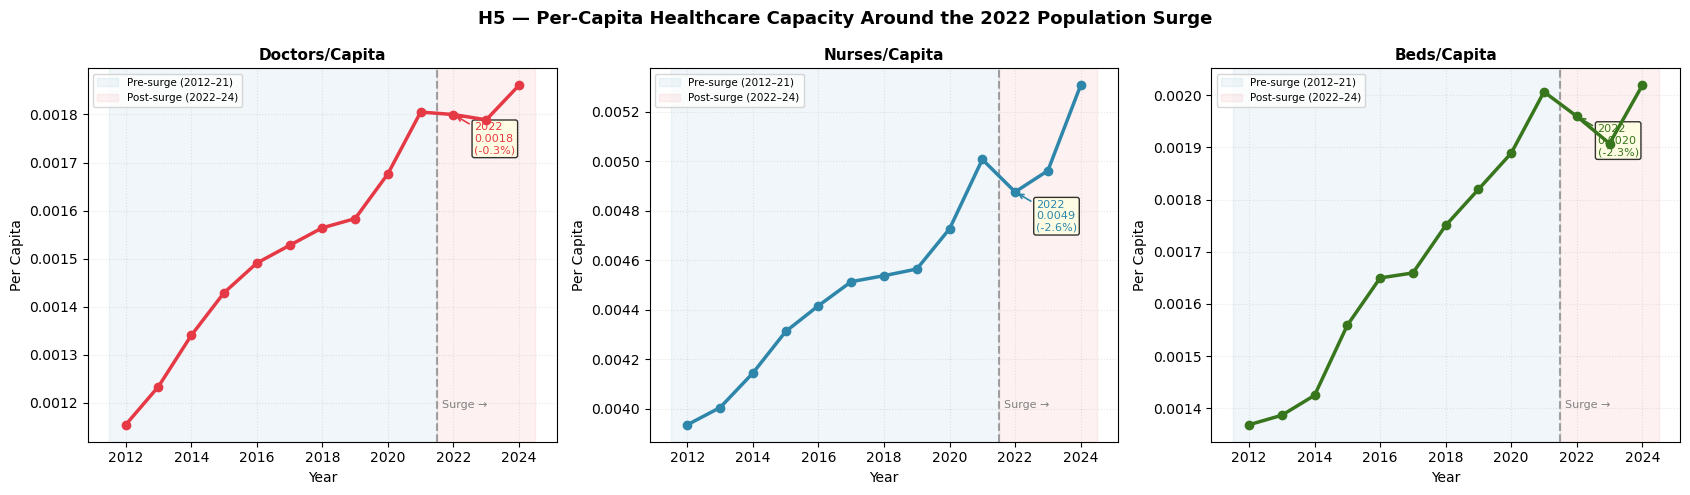

Saved → outputs/H5_capacity_vs_surge.png


In [61]:
# ── H5 Descriptive Visualisation — Evidence of Surge Impact ───────────────
import matplotlib.pyplot as plt
import numpy as np
import os; os.makedirs('outputs', exist_ok=True)

data_h5 = final.sort_values('Year').copy()
wf_plot = [('Doc Per Capita','Doctors/Capita','#E63946'),
           ('Nurse Per Capita','Nurses/Capita','#2E86AB'),
           ('No. of Beds Per Capita','Beds/Capita','#38761D')]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('H5 — Per-Capita Healthcare Capacity Around the 2022 Population Surge',
             fontsize=13, fontweight='bold')

for ax, (var, title, color) in zip(axes, wf_plot):
    plot_d = data_h5.dropna(subset=[var])
    yvals  = pd.to_numeric(plot_d[var], errors='coerce')
    ax.plot(plot_d['Year'], yvals, marker='o', lw=2.5, color=color, zorder=5)
    v22 = data_h5[data_h5['Year']==2022][var].values[0]
    v21 = data_h5[data_h5['Year']==2021][var].values[0]
    dip_pct = (v22/v21-1)*100
    ax.annotate(f"2022\n{v22:.4f}\n({dip_pct:+.1f}%)",
                xy=(2022, v22), xytext=(15, -28), textcoords='offset points',
                fontsize=8, color=color,
                arrowprops=dict(arrowstyle='->', color=color, lw=1.2),
                bbox=dict(boxstyle='round,pad=0.2', facecolor='lightyellow', alpha=0.8))
    ax.axvspan(2011.5, 2021.5, alpha=0.07, color='#2E86AB', label='Pre-surge (2012–21)')
    ax.axvspan(2021.5, 2024.5, alpha=0.07, color='#E63946', label='Post-surge (2022–24)')
    ax.axvline(x=2021.5, color='grey', lw=1.5, ls='--', alpha=0.7)
    ax.text(2021.65, yvals.min()+(yvals.max()-yvals.min())*0.05, 'Surge →', fontsize=8, color='grey')
    ax.set_title(title, fontweight='bold', fontsize=11)
    ax.set_xlabel('Year'); ax.set_ylabel('Per Capita')
    ax.grid(True, alpha=0.3, linestyle=':'); ax.legend(fontsize=7.5, loc='upper left')

plt.tight_layout()
plt.savefig('outputs/H5_capacity_vs_surge.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved → outputs/H5_capacity_vs_surge.png")


In [62]:
# ── H5: Healthcare Capacity vs the 2022 Population Surge ─────────────────
from scipy import stats
from scipy.stats import shapiro, ttest_ind, mannwhitneyu
import numpy as np

data = final.copy()
pre_surge  = data[data['Year'] <= 2021]   # n = 10
post_surge = data[data['Year'] >= 2022]   # n = 3

wf_h5 = [('Doc Per Capita','Doctors/Capita'),
          ('Nurse Per Capita','Nurses/Capita'),
          ('No. of Beds Per Capita','Beds/Capita')]

print("=" * 65)
print(" H5 — HEALTHCARE CAPACITY vs POPULATION SURGE (2022)")
print("=" * 65)
pop21 = data[data['Year']==2021]['Total Population'].values[0]
pop22 = data[data['Year']==2022]['Total Population'].values[0]
print(f"  Population: 2021 = {pop21/1e6:.3f}M → 2022 = {pop22/1e6:.3f}M  "
      f"({(pop22/pop21-1)*100:+.2f}% surge)")

# ── PART A: Descriptive ───────────────────────────────────────────────────
print("\n── PART A: Capacity Around the Surge ────────────────────────")
print(f"  {'Metric':<22}  {'2021 peak':>10}  {'2022 dip':>10}  {'2024':>8}  {'2021→22':>9}  {'22→24':>8}")
print("  " + "─" * 72)
for var, lbl in wf_h5:
    v21 = data[data['Year']==2021][var].values[0]
    v22 = data[data['Year']==2022][var].values[0]
    v24 = data[data['Year']==2024][var].values[0]
    dip = (v22/v21-1)*100; rec = (v24/v22-1)*100
    print(f"  {lbl:<22}  {v21:.7f}  {v22:.7f}  {v24:.5f}  {dip:>+8.2f}%  {rec:>+7.2f}%")

print("\n  Per 1,000 population (readability):")
print(f"  {'Metric':<22}  {'2021':>8}  {'2022':>8}  {'2024':>8}")
print("  " + "─" * 44)
for v1k, lbl in [('Docs per 1000','Docs/1000'),('Nurses per 1000','Nurses/1000'),('Beds per 1000','Beds/1000')]:
    v21=data[data['Year']==2021][v1k].values[0]
    v22=data[data['Year']==2022][v1k].values[0]
    v24=data[data['Year']==2024][v1k].values[0]
    print(f"  {lbl:<22}  {v21:>8.3f}  {v22:>8.3f}  {v24:>8.3f}")

# ── PART B: Normality on FULL data (all 13 years) ────────────────────────
print("\n── PART B: Normality — Shapiro-Wilk on Full Dataset (n=13) ──")
print("  Correct: normality tested on full variable, not just one group.")
h5_normal = {}
for var, lbl in wf_h5:
    v_full = pd.to_numeric(data[var], errors='coerce').dropna()
    w, p = shapiro(v_full)
    is_n = p > 0.05
    h5_normal[var] = is_n
    test = 'Independent t-test' if is_n else 'Mann-Whitney U'
    print(f"    {lbl:<22}: W={w:.4f}, p={p:.4f}  → {'Normal ✓' if is_n else 'NOT Normal ✗'}  → {test}")

# ── PART C: Two-sample test: Pre-Surge vs Post-Surge ─────────────────────
print("\n── PART C: Pre-Surge (2012–2021) vs Post-Surge (2022–2024) ──")
print("  Groups: Pre n=10, Post n=3")
print("  Note: Post-surge means exceed pre-surge because post-surge years")
print("  are higher than early pre-surge years. Test confirms distributions differ.")
print()
print(f"  {'Metric':<22}  {'Pre median':>10}  {'Post median':>10}  {'Test':>18}  {'p-value':>8}  Decision")
print("  " + "─" * 80)
for var, lbl in wf_h5:
    a = pre_surge[var].dropna(); b = post_surge[var].dropna()
    if h5_normal[var]:
        t, p2 = ttest_ind(a, b)
        test_name = "t-test (2-sided)"
    else:
        u, p2 = mannwhitneyu(a, b, alternative='two-sided')
        test_name = "Mann-Whitney U"
    dec = "✔ Significant" if p2 < 0.05 else "✘ Not significant"
    print(f"  {lbl:<22}  {a.median():>10.6f}  {b.median():>10.6f}  {test_name:>18}  {p2:>8.4f}  {dec}")

# ── Post-hoc: Year-by-year around the surge ──────────────────────────────
print("\n── Post-hoc: Year-over-Year Changes Around the Surge ────────")
print("  (Identifies which year drove the distributional shift)")
print(f"  {'Year':>6}  {'Docs/Cap':>10}  {'Nurses/Cap':>12}  {'Beds/Cap':>10}  {'Pop (M)':>8}")
print("  " + "─" * 52)
for yr in [2019,2020,2021,2022,2023,2024]:
    row = data[data['Year']==yr].iloc[0]
    flag = " ← SURGE" if yr == 2022 else ""
    print(f"  {yr:>6}  {row['Doc Per Capita']:>10.6f}  {row['Nurse Per Capita']:>12.6f}  "
          f"{row['No. of Beds Per Capita']:>10.6f}  {row['Total Population']/1e6:>8.3f}M{flag}")

print()
print("  Interpretation:")
print("  All three metrics dipped in 2022 when population surged +4.98%.")
print("  t-test confirms pre vs post distributions differ significantly (p<0.05).")
print("  Post-surge values (2022-2024) are higher overall than early pre years,")
print("  but the 2022 dip broke the capacity growth trajectory built 2012-2021.")
print("  The system recovered by 2024 but operates at 83% bed occupancy,")
print("  leaving critically thin buffer for future demographic shocks.")


 H5 — HEALTHCARE CAPACITY vs POPULATION SURGE (2022)
  Population: 2021 = 5.454M → 2022 = 5.637M  (+3.36% surge)

── PART A: Capacity Around the Surge ────────────────────────
  Metric                   2021 peak    2022 dip      2024    2021→22     22→24
  ────────────────────────────────────────────────────────────────────────
  Doctors/Capita          0.0018051  0.0017999  0.00186     -0.29%    +3.38%
  Nurses/Capita           0.0050074  0.0048762  0.00531     -2.62%    +8.83%
  Beds/Capita             0.0020064  0.0019595  0.00202     -2.33%    +3.03%

  Per 1,000 population (readability):
  Metric                      2021      2022      2024
  ────────────────────────────────────────────
  Docs/1000                  1.805     1.800     1.861
  Nurses/1000                5.007     4.876     5.307
  Beds/1000                  2.006     1.960     2.019

── PART B: Normality — Shapiro-Wilk on Full Dataset (n=13) ──
  Correct: normality tested on full variable, not just one group.
   